# Do albuminuria screening models remain reliable after a laboratory assay change?

**Temporal validation and explanation stability in NHANES**  
Research notebook prepared for **Partha Pratim Ray** · Google Colab T4-compatible

**Run in Colab.** Upload this `.ipynb`, then select **Runtime → Change runtime type → T4 GPU → Run all**. XGBoost uses CUDA when the startup probe succeeds. Data preparation, survey analysis, and fixed-background TreeSHAP run on the CPU. The notebook downloads public CDC files into memory and displays figures as 600-DPI PNGs in the cell outputs. Each figure is followed by its full underlying table. Tables are tab-separated for direct spreadsheet paste. Figure dimensions on screen are scaled for reading.

**Study question.** How much does a documented urinary albumin assay change alter the apparent performance of a frozen model, and does retraining with harmonized labels change which predictors the model uses?

| Analysis | What changes | What is held fixed |
|---|---|---|
| Primary temporal comparison | Reported versus harmonized later-period labels | Same participants, frozen earlier-period models, predicted scores and operating thresholds |
| Secondary explanation transport | Earlier versus later evaluation participants | Same frozen model and SHAP reference distribution |
| Secondary paired refits | Training label definition in the later period | Same training and evaluation participants, feature preprocessing, model settings and SHAP background |

**Outcome.** Concurrent elevated UACR (≥30 mg/g) measured once. This is a cross-sectional screening research endpoint. Persistent albuminuria and CKD require evidence of chronicity. The notebook treats SHAP as an explanation of model output. Clinical utility and causal effects require separate study.

**Analysis specification.** The primary estimand is the paired change in the survey-weighted XGBoost Brier score (harmonized minus reported labels) in the full later cycle. AUROC, average precision, calibration, threshold metrics and all SHAP analyses are secondary or exploratory. Later-cycle labels are used only for evaluation and the separately identified refit experiment. Commit this analysis specification before interpreting results. The assay equation estimates a comparable measurement and contains error. The paired comparison measures sensitivity to the label definition.

In [1]:
# Google Colab setup. Re-run this cell in a fresh runtime if libraries were already imported.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "xgboost==3.1.3", "shap==0.50.0",
    ])

## 1. Configuration and display conventions

All calculations use full precision. Printed tables are rounded to six significant digits. Confusion matrix counts are sample counts. Weighted rates and means use the appropriate examination weight for each cycle. Models use weights normalized to a mean of one within each training fit. The two survey cycles are never pooled for population estimation.

In [2]:
from concurrent.futures import ThreadPoolExecutor
from hashlib import sha256
from importlib.metadata import version
from io import BytesIO
from urllib.request import Request, urlopen
import json
import os
import time
import warnings

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import hadamard
from scipy.optimize import minimize, brentq
from scipy.special import expit, logit
from scipy.stats import t, spearmanr
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
import shap

SEED = 260731
DPI = 600
N_JOBS = min(4, os.cpu_count() or 1)
UACR_CUTOFF = 30.0
FAY = 0.5
TARGET_SENSITIVITY = 0.80
BACKGROUND_SIZE = 64
CYCLES = {
    "Earlier": {"year": "2017", "prefix": "P_", "suffix": "", "weight": "WTMECPRP", "label": "2017–Mar 2020"},
    "Later": {"year": "2021", "prefix": "", "suffix": "_L", "weight": "WTMEC2YR", "label": "Aug 2021–Aug 2023"},
}
COLORS = {"earlier": "#0072B2", "later": "#D55E00", "ink": "#222222", "muted": "#767676", "accent": "#009E73"}
plt.rcParams.update({
    "figure.dpi": DPI, "savefig.dpi": DPI, "figure.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.labelcolor": COLORS["ink"],
    "axes.grid": True, "grid.alpha": 0.22, "axes.axisbelow": True,
    "legend.frameon": False, "figure.constrained_layout.use": True,
})

def table(title, data):
    print(f"\n{title}\n")
    print(data.to_csv(sep="\t", index=False, float_format="%.6g", na_rep="NA").rstrip())

def show_figure(fig, *tables):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=DPI, facecolor="white")
    plt.close(fig)
    width = round(fig.get_figwidth() * 108)
    display(Image(data=buffer.getvalue(), width=width, format="png"))
    for title, data in tables:
        table(title, data)

def select_device():
    try:
        gpu = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=10, check=True)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)
            probe = XGBClassifier(device="cuda", tree_method="hist", n_estimators=1, n_jobs=1)
            probe.fit(np.arange(16, dtype=np.float32).reshape(8, 2), [0, 1] * 4)
        device = json.loads(probe.get_booster().save_config())["learner"]["generic_param"]["device"]
        if device.startswith("cuda"):
            return "cuda", gpu.stdout.strip().splitlines()[0]
    except (OSError, RuntimeError, subprocess.SubprocessError) as exc:
        return "cpu", f"CPU fallback ({type(exc).__name__})"
    return "cpu", "CUDA probe returned CPU"

DEVICE, DEVICE_NAME = select_device()
print(f"XGBoost training device: {DEVICE} | {DEVICE_NAME}")
table("Software versions", pd.DataFrame([
    ("Python", sys.version.split()[0]),
    *[(name, version(name)) for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "xgboost", "shap"]],
], columns=["Package", "Version"]))

XGBoost training device: cuda | Tesla T4

Software versions

Package	Version
Python	3.13.16
numpy	2.4.6
pandas	2.2.3
scipy	1.16.3
scikit-learn	1.6.1
matplotlib	3.10.0
xgboost	3.1.3
shap	0.50.0


## 2. Download and harmonize the two public use cycles

Use the CDC 2017–March 2020 pre-pandemic release as published. The standalone 2017–2018 sample overlaps that release. For the later cycle, transform urinary albumin to the earlier assay scale using the CDC backward Deming equation, `old = −1.643 + 1.189 × new` in mg/L. Leave urinary creatinine on its reported scale per the CDC bridging note. Compute UACR as `100 × albumin / creatinine`, rounded to the released precision of two decimals. Clip negative fitted concentrations at zero to retain a physically meaningful concentration and report the number clipped. Zero clipping leaves the binary threshold at 30 mg/g unaffected. The primary analysis uses a shared sample with usable UACR outcomes under both definitions.

**Sources.** [Earlier CDC files and guidance](https://wwwn.cdc.gov/nchs/nhanes/search/DataPage.aspx?Cycle=2017-2020) · [Later CDC files and guidance](https://wwwn.cdc.gov/nchs/nhanes/search/DataPage.aspx?Cycle=2021-2023) · [CDC assay bridging equations](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/ALB_CR_L.htm) · [KDIGO 2024 guideline](https://kdigo.org/wp-content/uploads/2024/03/KDIGO-2024-CKD-Guideline.pdf)

In [3]:
BASE_URL = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public"
MODULES = {
    "DEMO": ["RIDAGEYR", "RIAGENDR", "RIDEXPRG", "RIDSTATR", "SDMVSTRA", "SDMVPSU"],
    "BMX": ["BMXBMI", "BMXWAIST"],
    "BPXO": [f"BPXO{kind}{i}" for kind in ["SY", "DI"] for i in range(1, 4)],
    "SMQ": ["SMQ020"], "DIQ": ["DIQ010"],
    "ALB_CR": ["URXUMA", "URXUCR", "URDACT"],
}
FEATURES = ["Age", "Female", "BMI", "Waist", "Systolic BP", "Diastolic BP", "Ever smoked 100 cigarettes", "Diagnosed diabetes", "Borderline diabetes"]
BINARY = ["Female", "Ever smoked 100 cigarettes", "Diagnosed diabetes", "Borderline diabetes"]
CONTINUOUS = [name for name in FEATURES if name not in BINARY]

def fetch_module(job):
    cycle, module = job
    cfg = CYCLES[cycle]
    name = cfg["prefix"] + module + cfg["suffix"]
    url = f"{BASE_URL}/{cfg['year']}/DataFiles/{name}.xpt"
    for attempt in range(3):
        try:
            request = Request(url, headers={"User-Agent": "Python NHANES research notebook"})
            with urlopen(request, timeout=45) as response:
                payload = response.read()
            values = pd.read_sas(BytesIO(payload), format="xport")
            break
        except (OSError, ValueError) as exc:
            if attempt == 2:
                raise RuntimeError(f"Could not read CDC XPT: {url}") from exc
            time.sleep(2 ** attempt)
    cols = ["SEQN"] + MODULES[module] + ([cfg["weight"]] if module == "DEMO" else [])
    absent = set(cols) - set(values.columns)
    if absent:
        raise ValueError(f"{name} is missing expected columns: {sorted(absent)}")
    data = values.loc[:, cols].copy()
    if data.SEQN.isna().any() or not data.SEQN.is_unique:
        raise ValueError(f"Invalid participant identifiers in {name}")
    data.SEQN = data.SEQN.astype("int64")
    record = {"Cycle": cycle, "File": name, "Rows": len(data), "SHA-256": sha256(payload).hexdigest(), "URL": url}
    return job, data, record

with ThreadPoolExecutor(max_workers=4) as pool:
    downloaded = list(pool.map(fetch_module, [(c, m) for c in CYCLES for m in MODULES]))
raw = {job: frame for job, frame, _ in downloaded}
table("CDC input provenance", pd.DataFrame([record for _, _, record in downloaded]))


CDC input provenance

Cycle	File	Rows	SHA-256	URL
Earlier	P_DEMO	15560	2e46c6c26bf77cd8989f64011ace12cbf42c0f3e03414eb59acc5328c8f87913	https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DEMO.xpt
Earlier	P_BMX	14300	7038d0da3169420a4a3cbaec09ac586a701b38e1c7b925431b60e13ac24fed66	https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_BMX.xpt
Earlier	P_BPXO	11656	5edbcb81e99fe8dad38deb8b642570278b200c525d88ffa29ae3ceb4dd38bde4	https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_BPXO.xpt
Earlier	P_SMQ	11137	29b7f6c59ab570c042c866312f0eb4329009e85fadbda6f9427a8bf31ecb3a3f	https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_SMQ.xpt
Earlier	P_DIQ	14986	79153f799fc2171792771c4aa250029c62807f14915f1f81405b03233b1e5ae3	https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DIQ.xpt
Earlier	P_ALB_CR	13027	c493f6b74cc0608bb7083b92e074fc3070b9e614fd5e1e34d0ce943e0f6116bf	https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_ALB_CR.xpt
Later	DEM

In [4]:
def harmonized_uacr(albumin, creatinine, intercept=-1.643, slope=1.189):
    old_albumin = (intercept + slope * albumin).clip(lower=0)
    return (100 * old_albumin / creatinine.where(creatinine.gt(0))).round(2)

def indicator(series, positive, known):
    return series.eq(positive).astype(float).where(series.isin(known))

def make_cohort(cycle):
    d = raw[(cycle, "DEMO")].rename(columns={CYCLES[cycle]["weight"]: "w"})
    for module in MODULES:
        if module != "DEMO":
            d = d.merge(raw[(cycle, module)], on="SEQN", how="left", validate="one_to_one")
    flow = []
    def restrict(label, mask):
        nonlocal d
        before = len(d)
        d = d.loc[mask].copy()
        flow.append({"Cycle": cycle, "Stage": label, "Retained": len(d), "Removed at stage": before - len(d)})

    restrict("Demographic records", pd.Series(True, index=d.index))
    restrict("Age 20 or older", d.RIDAGEYR.ge(20))
    restrict("MEC examined with positive weight and valid design fields",
             d.RIDSTATR.eq(2) & d.w.gt(0) & d[["SDMVSTRA", "SDMVPSU"]].notna().all(axis=1))
    restrict("Exclude known pregnancy", d.RIDEXPRG.ne(1))
    restrict("Recorded UACR and usable albumin / creatinine", d.URDACT.ge(0) & d.URXUMA.ge(0) & d.URXUCR.gt(0))
    d["Age"] = d.RIDAGEYR
    d["Female"] = indicator(d.RIAGENDR, 2, [1, 2])
    d["BMI"] = d.BMXBMI.where(d.BMXBMI.gt(0))
    d["Waist"] = d.BMXWAIST.where(d.BMXWAIST.gt(0))
    for kind, name in [("SY", "Systolic BP"), ("DI", "Diastolic BP")]:
        cols = [f"BPXO{kind}{i}" for i in range(1, 4)]
        readings = d[cols]
        d[name] = readings.where(readings.gt(0)).mean(axis=1)
    d["Ever smoked 100 cigarettes"] = indicator(d.SMQ020, 1, [1, 2])
    d["Diagnosed diabetes"] = indicator(d.DIQ010, 1, [1, 2, 3])
    d["Borderline diabetes"] = indicator(d.DIQ010, 3, [1, 2, 3])
    d["uacr_reported"] = d.URDACT
    d["y_reported"] = d.uacr_reported.ge(UACR_CUTOFF).astype(int)
    if cycle == "Later":
        d["uacr_harmonized"] = harmonized_uacr(d.URXUMA, d.URXUCR)
        if d.uacr_harmonized.isna().any():
            raise ValueError("Paired outcome sample contains an undefined harmonized UACR")
        d["y_harmonized"] = d.uacr_harmonized.ge(UACR_CUTOFF).astype(int)
        d["albumin_clipped"] = (-1.643 + 1.189 * d.URXUMA).lt(0)
    return d.reset_index(drop=True), flow

old, old_flow = make_cohort("Earlier")
new, new_flow = make_cohort("Later")
flow = pd.DataFrame(old_flow + new_flow)
assert not set(old.SEQN).intersection(new.SEQN), "Cohorts must be disjoint"
assert not set(FEATURES).intersection({"SEQN", "w", "URXUMA", "URXUCR", "URDACT", "y_reported", "y_harmonized"})
assert (new.y_reported != new.y_harmonized).any(), "No paired relabelling detected"
for cohort in [old, new]:
    assert cohort[FEATURES].notna().any(axis=0).all(), "A predictor is entirely missing"
    recalculated = 100 * cohort.URXUMA / cohort.URXUCR
    within = np.isclose(recalculated, cohort.URDACT, atol=0.011, rtol=0)
    print(f"Released ratio reproduced within 0.011 mg/g in {within.mean():.2%} of {len(cohort):,} records")
table("Participant flow and exclusions", flow)
table("Assay preprocessing checks", pd.DataFrame([{
    "Later participants": len(new), "Negative fitted albumin clipped": int(new.albumin_clipped.sum()),
    "Reported positives": new.y_reported.sum(), "Harmonized positives": new.y_harmonized.sum(),
    "Changed labels": new.y_reported.ne(new.y_harmonized).sum(),
}]))

Released ratio reproduced within 0.011 mg/g in 100.00% of 8,234 records
Released ratio reproduced within 0.011 mg/g in 100.00% of 5,870 records

Participant flow and exclusions

Cycle	Stage	Retained	Removed at stage
Earlier	Demographic records	15560	0
Earlier	Age 20 or older	9232	6328
Earlier	MEC examined with positive weight and valid design fields	8544	688
Earlier	Exclude known pregnancy	8457	87
Earlier	Recorded UACR and usable albumin / creatinine	8234	223
Later	Demographic records	11933	0
Later	Age 20 or older	7809	4124
Later	MEC examined with positive weight and valid design fields	6064	1745
Later	Exclude known pregnancy	6023	41
Later	Recorded UACR and usable albumin / creatinine	5870	153

Assay preprocessing checks

Later participants	Negative fitted albumin clipped	Reported positives	Harmonized positives	Changed labels
5870	423	719	785	78


## 3. Exploratory data analysis and assay shifts

Describe available survey-weighted feature values and missingness. Standardized differences show the magnitude of cross-cycle shifts without using significance testing to select predictors. For continuous features, the standardized difference is the difference in weighted means divided by the square root of the mean of the two weighted variances. The same formula applies to binary indicators with their weighted Bernoulli variances. Descriptive plots are generated after defining the predictor list and analysis settings.

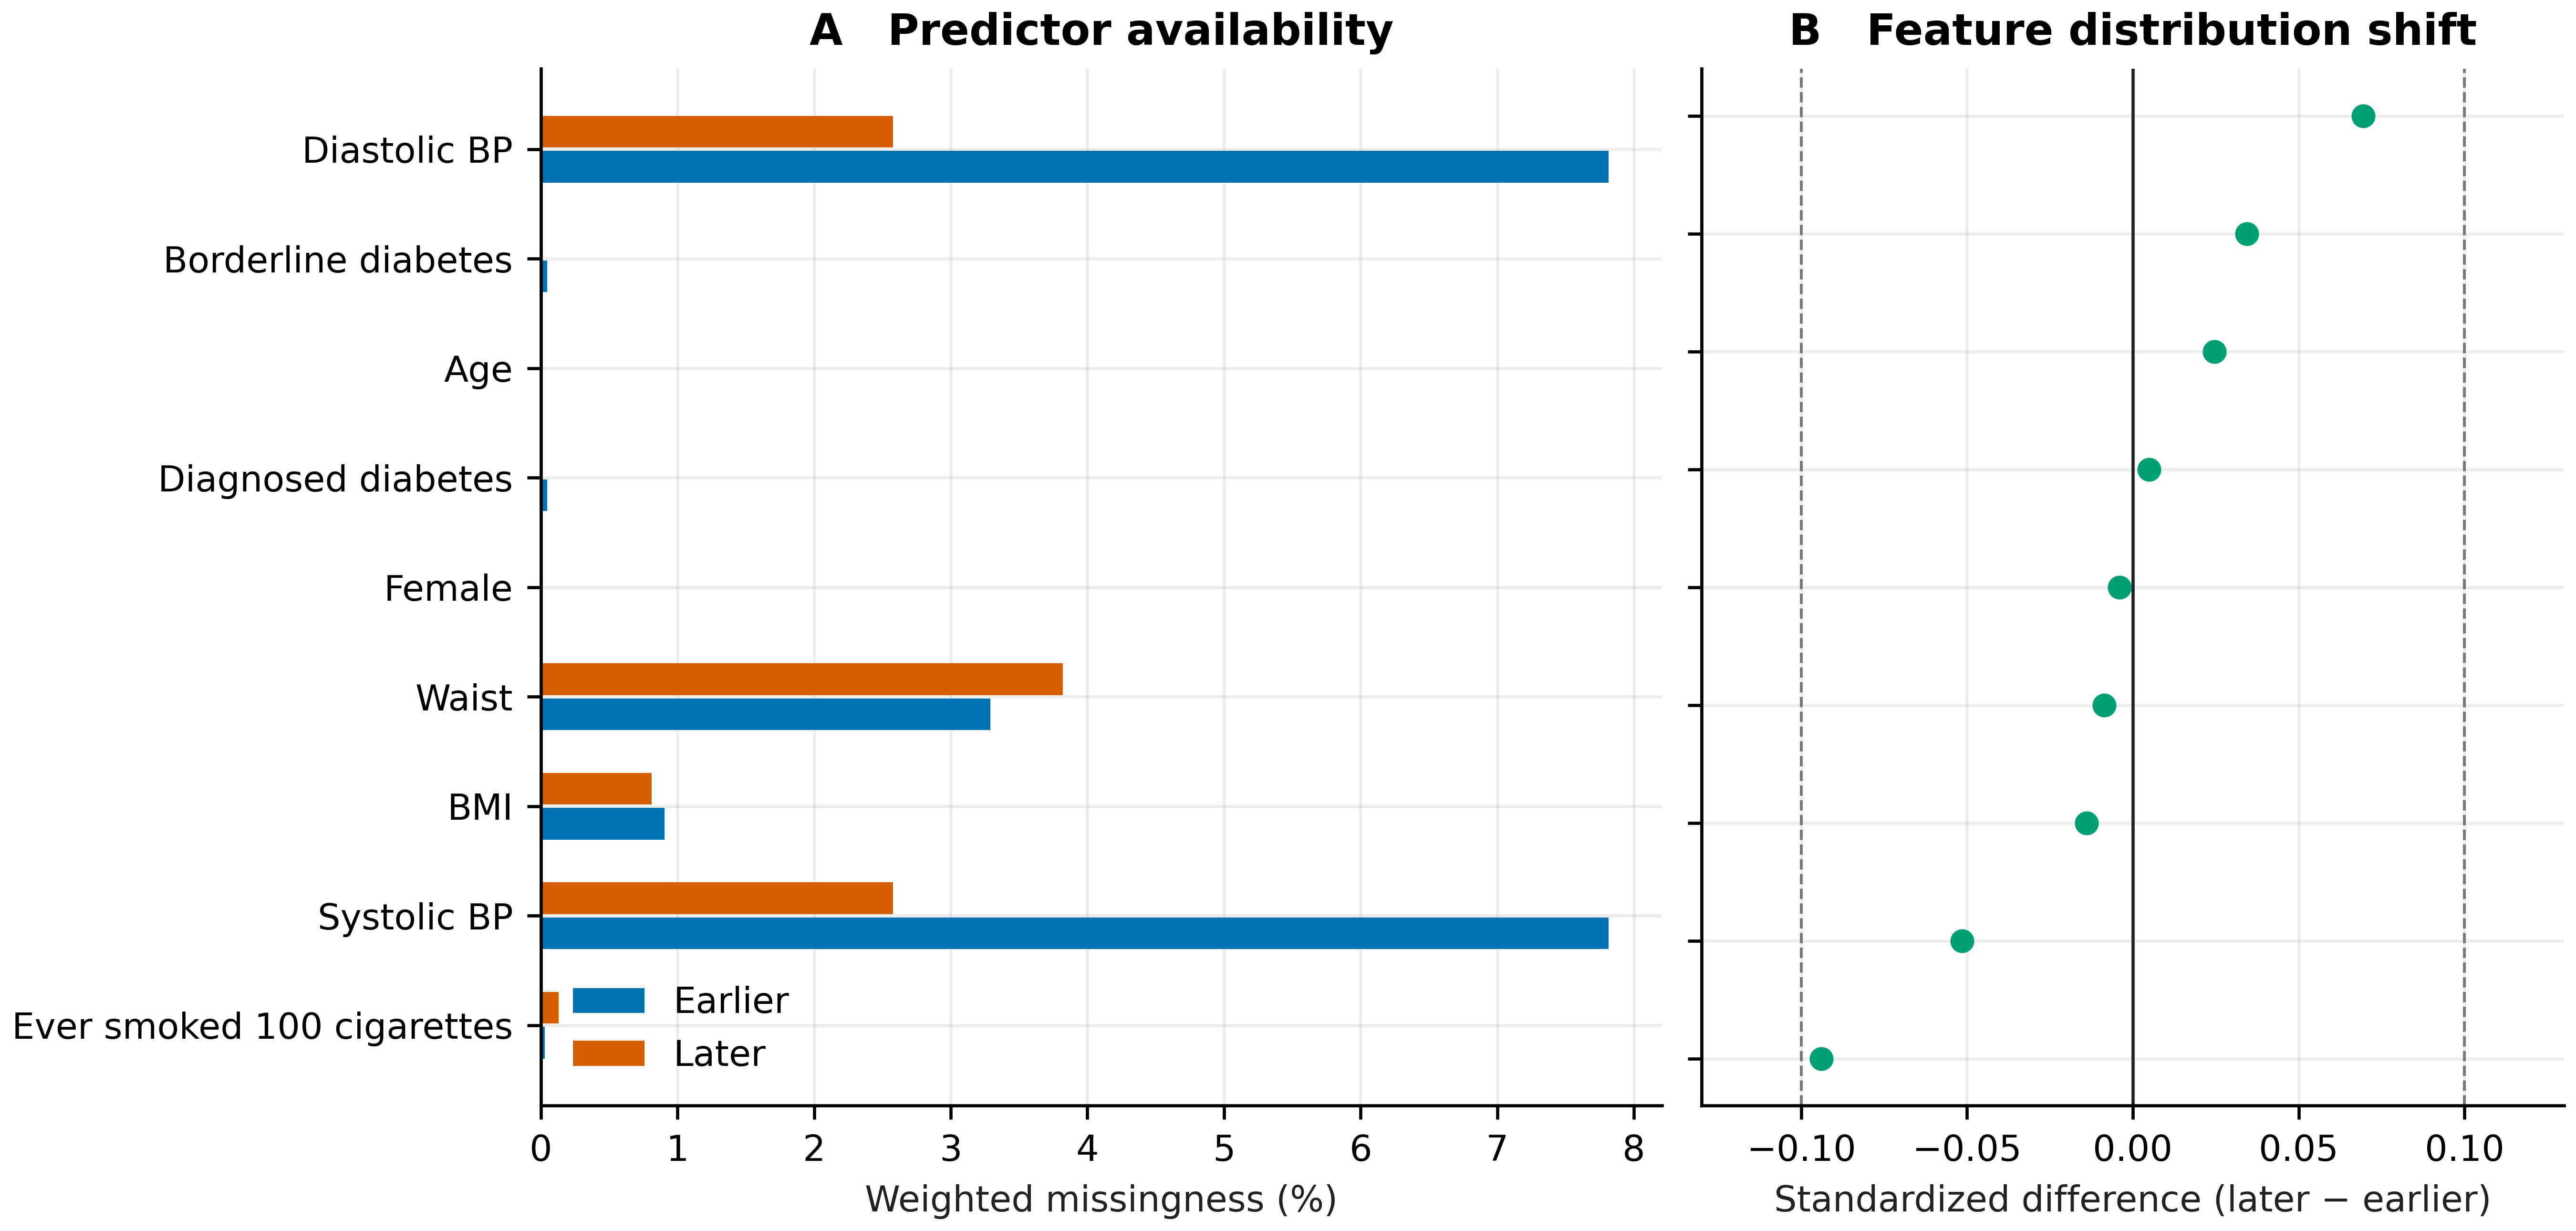


Table 1. Full cohort predictor summary

Cycle	Predictor	Available n	Missing n	Weighted missing %	Weighted mean or proportion	Weighted SD	Weighted Q1	Weighted median	Weighted Q3
Earlier	Age	8234	0	0	48.4781	17.27	33	48	62
Earlier	Female	8234	0	0	0.513387	0.499821	0	1	1
Earlier	BMI	8124	110	0.904377	29.7881	7.28797	24.7	28.6	33.511
Earlier	Waist	7873	361	3.29099	100.605	17.0516	88.4	99.1	111.1
Earlier	Systolic BP	7438	796	7.81468	122.058	17.3188	109.667	119.667	131.333
Earlier	Diastolic BP	7438	796	7.81468	74.0413	10.8798	66.6667	73.3333	81
Earlier	Ever smoked 100 cigarettes	8230	4	0.0272561	0.426181	0.494521	0	0	1
Earlier	Diagnosed diabetes	8231	3	0.04741	0.115491	0.319614	0	0	0
Earlier	Borderline diabetes	8231	3	0.04741	0.0249981	0.156119	0	0	0
Later	Age	5870	0	0	48.903	17.3408	34	49	63
Later	Female	5870	0	0	0.511389	0.49987	0	1	1
Later	BMI	5807	63	0.811424	29.686	7.2628	24.6	28.3	33.3
Later	Waist	5638	232	3.82015	100.458	16.9563	88.1	98.8	110.9
Later	Systolic BP	5711	159	2.57628	121.

In [5]:
def wmean(x, w):
    return np.average(np.asarray(x), weights=np.asarray(w))

def wquantile(x, q, w):
    x, w = np.asarray(x), np.asarray(w)
    q = np.asarray(q)
    keep = np.isfinite(x) & np.isfinite(w) & (w > 0)
    order = np.argsort(x[keep], kind="stable")
    xs, ws = x[keep][order], w[keep][order]
    if len(xs) == 0:
        return np.full(q.shape, np.nan)
    locations = (np.cumsum(ws) - 0.5 * ws) / ws.sum()
    return np.interp(q, locations, xs)

eda_rows = []
for label, cohort in [("Earlier", old), ("Later", new)]:
    for name in FEATURES:
        valid = cohort[name].notna()
        x, w = cohort.loc[valid, name], cohort.loc[valid, "w"]
        mu = wmean(x, w)
        q1, median, q3 = wquantile(x, [0.25, 0.50, 0.75], w)
        eda_rows.append({"Cycle": label, "Predictor": name, "Available n": valid.sum(),
                         "Missing n": (~valid).sum(), "Weighted missing %": 100 * wmean(~valid, cohort.w),
                         "Weighted mean or proportion": mu, "Weighted SD": np.sqrt(wmean((x - mu) ** 2, w)),
                         "Weighted Q1": q1, "Weighted median": median, "Weighted Q3": q3})
eda = pd.DataFrame(eda_rows)
ed0, ed1 = [eda[eda.Cycle.eq(c)].set_index("Predictor") for c in CYCLES]
smd = (ed1["Weighted mean or proportion"] - ed0["Weighted mean or proportion"]) / np.sqrt(
    (ed0["Weighted SD"] ** 2 + ed1["Weighted SD"] ** 2) / 2
).replace(0, np.nan)
shift = pd.DataFrame({"Predictor": smd.index, "Standardized difference": smd.values}).sort_values("Standardized difference")
fig, ax = plt.subplots(1, 2, figsize=(9.0, 4.3), gridspec_kw={"width_ratios": [1.30, 1]})
ys = np.arange(len(shift))
for delta, cycle, color in [(-0.16, "Earlier", COLORS["earlier"]), (0.16, "Later", COLORS["later"])]:
    subset = eda[eda.Cycle.eq(cycle)].set_index("Predictor").loc[shift.Predictor]
    ax[0].barh(ys + delta, subset["Weighted missing %"], color=color, height=0.29, label=cycle)
ax[0].set(yticks=ys, yticklabels=shift.Predictor, xlabel="Weighted missingness (%)", title="A   Predictor availability")
ax[0].legend(loc="best")
ax[1].axvline(0, color=COLORS["ink"], linewidth=0.8)
ax[1].axvline(-0.1, color=COLORS["muted"], linestyle="--", linewidth=0.7)
ax[1].axvline(0.1, color=COLORS["muted"], linestyle="--", linewidth=0.7)
ax[1].scatter(shift["Standardized difference"], ys, color=COLORS["accent"], s=25, zorder=3)
ax[1].set(yticks=ys, yticklabels=[], xlim=(min(-0.13, smd.min() - 0.03), max(0.13, smd.max() + 0.03)),
          xlabel="Standardized difference (later − earlier)", title="B   Feature distribution shift")
show_figure(fig, ("Table 1. Full cohort predictor summary", eda), ("Figure 1B values", shift))

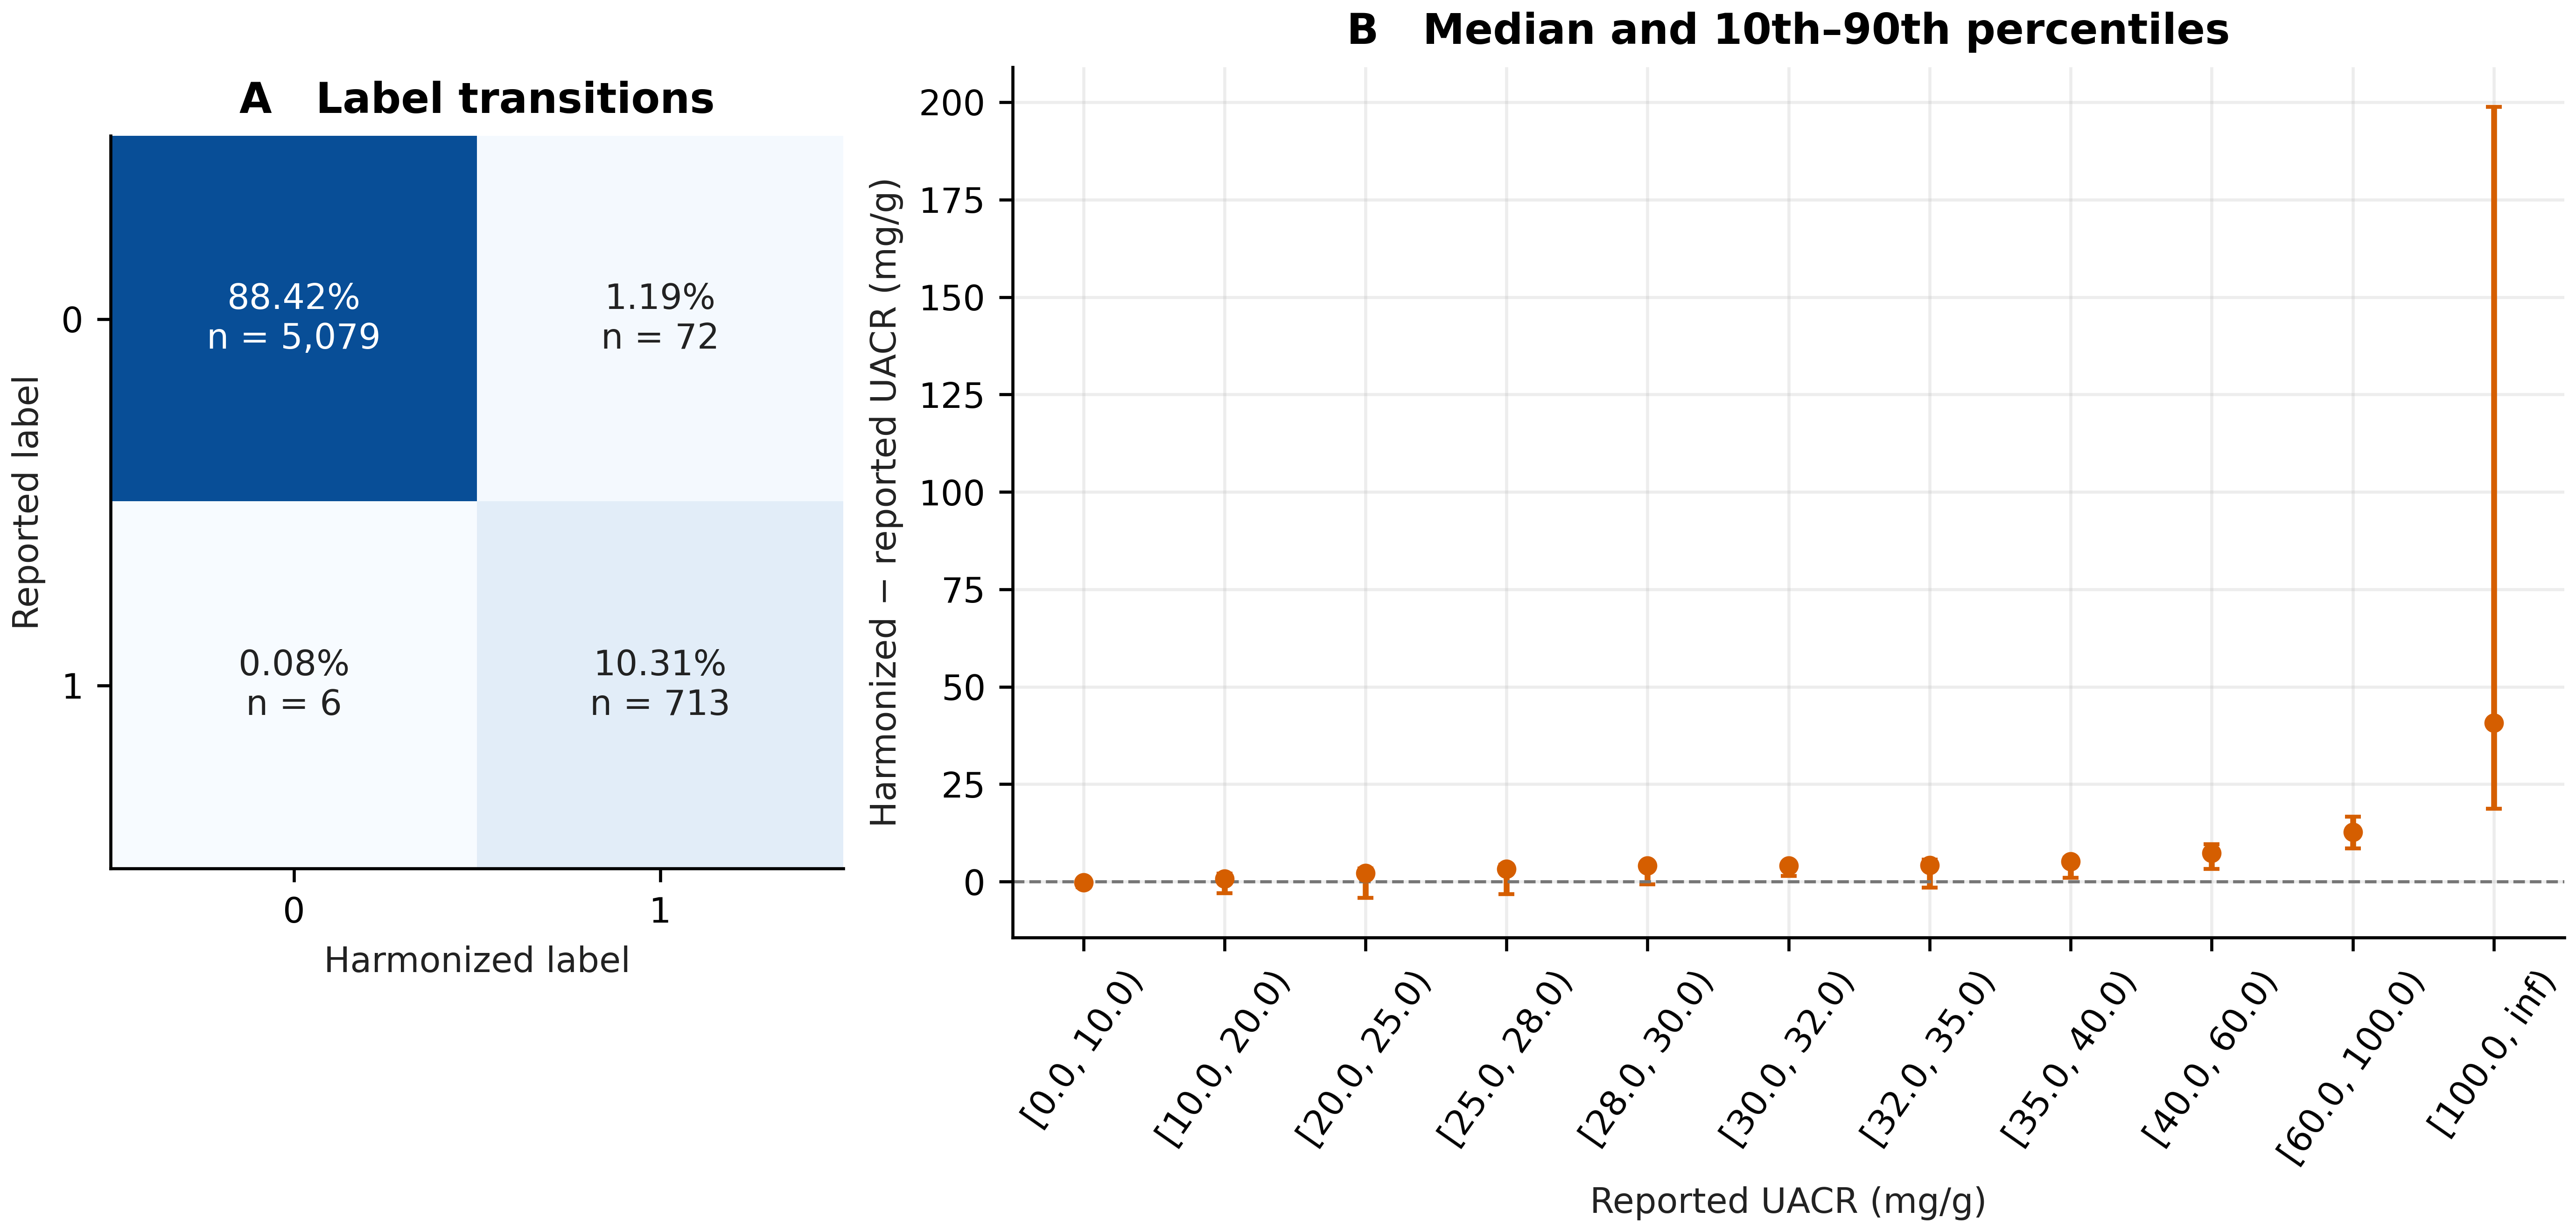


Table 2. Paired label transitions in the later cycle

Reported label	Harmonized label	Sample n	Weighted % of cohort
0	0	5079	88.4162
0	1	72	1.1907
1	0	6	0.0848116
1	1	713	10.3083

Figure 2B values

Reported UACR band	Sample n	Change P10	Change median	Change P90	Changed n	Weighted changed %
[0.0, 10.0)	3539	-1.36198	-0.17	0.54	0	0
[10.0, 20.0)	1232	-2.93426	0.8	2.11	0	0
[20.0, 25.0)	237	-4.16268	2.12	3.37783	0	0
[25.0, 28.0)	89	-3.22416	3.21548	4.28037	30	32.0084
[28.0, 30.0)	54	-0.731291	4.13838	4.8543	42	84.3533
[30.0, 32.0)	27	1.41037	4.08717	4.96699	2	4.84466
[32.0, 35.0)	59	-1.4979	4.23994	5.62605	3	7.291
[35.0, 40.0)	82	1.01908	5.18182	6.1785	1	0.940939
[40.0, 60.0)	176	3.27094	7.27798	9.60727	0	0
[60.0, 100.0)	124	8.4792	12.71	16.6173	0	0
[100.0, inf)	251	18.6502	40.7511	198.827	0	0


In [6]:
transition_rows = []
for a in [0, 1]:
    for b in [0, 1]:
        mask = new.y_reported.eq(a) & new.y_harmonized.eq(b)
        transition_rows.append((a, b, mask.sum(), 100 * wmean(mask, new.w)))
transitions = pd.DataFrame(transition_rows, columns=["Reported label", "Harmonized label", "Sample n", "Weighted % of cohort"])
intervals = [0, 10, 20, 25, 28, 30, 32, 35, 40, 60, 100, np.inf]
assay = new.assign(band=pd.cut(new.uacr_reported, intervals, right=False, include_lowest=True))
assay_rows = []
for band, sub in assay.groupby("band", observed=True):
    delta = sub.uacr_harmonized - sub.uacr_reported
    quantiles = wquantile(delta, [0.10, 0.50, 0.90], sub.w)
    assay_rows.append((str(band), len(sub), *quantiles, sub.y_reported.ne(sub.y_harmonized).sum(),
                       100 * wmean(sub.y_reported.ne(sub.y_harmonized), sub.w)))
assay_bands = pd.DataFrame(assay_rows, columns=["Reported UACR band", "Sample n", "Change P10", "Change median", "Change P90", "Changed n", "Weighted changed %"])
fig, ax = plt.subplots(1, 2, figsize=(9.2, 4.4), gridspec_kw={"width_ratios": [0.85, 1.8]})
mat = transitions["Weighted % of cohort"].to_numpy().reshape(2, 2)
ax[0].imshow(mat, cmap="Blues", vmin=0, vmax=100)
for i in range(2):
    for j in range(2):
        row = transitions.iloc[2 * i + j]
        ax[0].text(j, i, f"{mat[i,j]:.2f}%\nn = {int(row['Sample n']):,}", ha="center", va="center",
                   color="white" if mat[i, j] > 50 else COLORS["ink"])
ax[0].grid(False)
ax[0].set(xticks=[0, 1], yticks=[0, 1], xlabel="Harmonized label", ylabel="Reported label", title="A   Label transitions")
xs = np.arange(len(assay_bands))
mids = assay_bands["Change median"]
ax[1].errorbar(xs, mids, yerr=[mids - assay_bands["Change P10"], assay_bands["Change P90"] - mids],
               fmt="o", markersize=4, color=COLORS["later"], capsize=2)
ax[1].axhline(0, linestyle="--", color=COLORS["muted"], linewidth=0.8)
ax[1].set(xticks=xs, xticklabels=assay_bands["Reported UACR band"], ylabel="Harmonized − reported UACR (mg/g)",
          xlabel="Reported UACR (mg/g)", title="B   Median and 10th–90th percentiles")
ax[1].tick_params(axis="x", labelrotation=55)
show_figure(fig, ("Table 2. Paired label transitions in the later cycle", transitions), ("Figure 2B values", assay_bands))

## 4. Split first, fit within each training partition

The earlier cycle supplies a PSU-grouped internal test and development set. Three-fold grouped out-of-fold predictions within development select model-specific thresholds targeting ≥80% weighted sensitivity. The lower-complexity age-and-sex model is a reference. Logistic regression and XGBoost use the full predictor set. The XGBoost configuration is fixed in advance, allowing the paired refit to hold model complexity constant. Continuous features use fold-fitted median imputation and binary features use fold-fitted modal imputation. Scaling belongs inside the logistic pipelines. The complete later cycle is untouched by all earlier-cycle fitting and threshold selection.

The refit comparison uses a later-cycle 70/30 split sampled within PSU with one fixed seed, independently of observed labels. Test memberships and original sampling weights are shared by both refits. The PSU-level design inference for this random-split subset is an approximation conditional on the realized split and fitted models.

In [7]:
def psu_id(d):
    return d.SDMVSTRA.astype(int).astype(str) + ":" + d.SDMVPSU.astype(int).astype(str)

def make_preprocessor(columns):
    from sklearn.compose import ColumnTransformer
    numeric = [name for name in columns if name in CONTINUOUS]
    binary = [name for name in columns if name in BINARY]
    prep = ColumnTransformer([
        ("continuous", SimpleImputer(strategy="median", keep_empty_features=True), numeric),
        ("binary", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary),
    ], verbose_feature_names_out=False)
    return prep.set_output(transform="pandas")

MODEL_NAMES = ["Age + sex", "Logistic regression", "XGBoost"]
XGB_SETTINGS = dict(n_estimators=240, max_depth=3, min_child_weight=12, learning_rate=0.035,
                    subsample=1.0, colsample_bytree=1.0, reg_lambda=5.0,
                    tree_method="hist", objective="binary:logistic", eval_metric="logloss",
                    random_state=SEED, n_jobs=N_JOBS, device=DEVICE)

def build_estimator(name):
    if name == "XGBoost":
        return XGBClassifier(**XGB_SETTINGS)
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))

def fit_estimator(name, x, y, w):
    model = build_estimator(name)
    norm = np.asarray(w) / np.mean(w)
    if name == "XGBoost":
        model.fit(x, y, sample_weight=norm)
        if DEVICE == "cuda":
            # Keep training on CUDA and use CPU for pandas inference and fixed-background SHAP.
            model.set_params(device="cpu")
    else:
        model.fit(x, y, standardscaler__sample_weight=norm, logisticregression__sample_weight=norm)
    return model

def fit_pipeline(name, train):
    cols = ["Age", "Female"] if name == "Age + sex" else FEATURES
    prep = make_preprocessor(cols)
    x = prep.fit_transform(train[cols])
    model = fit_estimator(name, x, train.y_reported, train.w)
    return prep, model, cols

def predict_pipeline(bundle, data):
    prep, model, cols = bundle
    return model.predict_proba(prep.transform(data[cols]))[:, 1]

def choose_threshold(y, p, w):
    scores = pd.DataFrame({"Probability": p, "Positive weight": np.asarray(y) * np.asarray(w)})
    by_score = scores.groupby("Probability", sort=True)["Positive weight"].sum().iloc[::-1]
    sensitivity = by_score.cumsum() / by_score.sum()
    return float(sensitivity.loc[sensitivity.ge(TARGET_SENSITIVITY)].index[0])

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
assert psu_id(old).nunique() >= outer.n_splits
train_pos, test_pos = next(outer.split(old, old.y_reported, groups=psu_id(old)))
old_train, old_test = old.iloc[train_pos].reset_index(drop=True), old.iloc[test_pos].reset_index(drop=True)
assert set(psu_id(old_train)).isdisjoint(psu_id(old_test))
inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 1)
folds = list(inner.split(old_train, old_train.y_reported, groups=psu_id(old_train)))
for tr, va in folds:
    assert set(psu_id(old_train.iloc[tr])).isdisjoint(psu_id(old_train.iloc[va]))
    assert old_train.y_reported.iloc[tr].nunique() == old_train.y_reported.iloc[va].nunique() == 2

rng = np.random.default_rng(SEED + 2)
refit_test_indices = []
for _, group in new.groupby(psu_id(new), sort=True):
    count = max(1, min(len(group) - 1, round(0.30 * len(group))))
    if len(group) < 2:
        raise ValueError("A PSU is too small for paired refit partitioning")
    refit_test_indices.extend(rng.choice(group.index, size=count, replace=False))
refit_test = new.loc[sorted(refit_test_indices)].copy()
refit_train = new.drop(index=refit_test.index).copy()
assert refit_train.index.intersection(refit_test.index).empty
assert len(refit_train) + len(refit_test) == len(new)
split_table = pd.DataFrame([
    (name, len(frame), psu_id(frame).nunique(), frame.y_reported.sum(), frame.y_harmonized.sum() if "y_harmonized" in frame else np.nan)
    for name, frame in [("Earlier development", old_train), ("Earlier grouped test", old_test),
                        ("Later frozen-model test", new), ("Later refit training", refit_train), ("Later refit test", refit_test)]
], columns=["Partition", "Sample n", "Masked PSUs", "Reported positives", "Harmonized positives"])
table("Table 3. Split audit", split_table)
table("XGBoost settings fixed before temporal evaluation", pd.DataFrame(list(XGB_SETTINGS.items()), columns=["Setting", "Value"]))


Table 3. Split audit

Partition	Sample n	Masked PSUs	Reported positives	Harmonized positives
Earlier development	6586	39	940	NA
Earlier grouped test	1648	10	223	NA
Later frozen-model test	5870	30	719	785
Later refit training	4105	30	494	541
Later refit test	1765	30	225	244

XGBoost settings fixed before temporal evaluation

Setting	Value
n_estimators	240
max_depth	3
min_child_weight	12
learning_rate	0.035
subsample	1.0
colsample_bytree	1.0
reg_lambda	5.0
tree_method	hist
objective	binary:logistic
eval_metric	logloss
random_state	260731
n_jobs	2
device	cuda


In [8]:
frozen, thresholds, oof_scores = {}, {}, {}
training_rows = []
for model_name in MODEL_NAMES:
    p = np.full(len(old_train), np.nan)
    for train_idx, val_idx in folds:
        bundle = fit_pipeline(model_name, old_train.iloc[train_idx])
        p[val_idx] = predict_pipeline(bundle, old_train.iloc[val_idx])
    assert np.isfinite(p).all()
    oof_scores[model_name] = p
    cutoff = choose_threshold(old_train.y_reported, p, old_train.w)
    thresholds[model_name] = cutoff
    positive = old_train.y_reported.eq(1).to_numpy()
    training_rows.append({"Model": model_name, "Frozen cutoff": cutoff,
                          "OOF weighted AUROC": roc_auc_score(old_train.y_reported, p, sample_weight=old_train.w),
                          "OOF weighted sensitivity": wmean(p[positive] >= cutoff, old_train.w[positive])})
    frozen[model_name] = fit_pipeline(model_name, old_train)

p_old = {name: predict_pipeline(bundle, old_test) for name, bundle in frozen.items()}
p_new = {name: predict_pipeline(bundle, new) for name, bundle in frozen.items()}
for scores in [p_old, p_new]:
    assert all(np.isfinite(p).all() and np.all((0 <= p) & (p <= 1)) for p in scores.values())
table("Earlier development only. Out-of-fold metrics and frozen cutoffs", pd.DataFrame(training_rows))


Earlier development only. Out-of-fold metrics and frozen cutoffs

Model	Frozen cutoff	OOF weighted AUROC	OOF weighted sensitivity
Age + sex	0.0761409	0.636616	0.806509
Logistic regression	0.0598665	0.700394	0.801082
XGBoost	0.0555973	0.705291	0.802355


## 5. Survey-weighted prediction metrics and paired uncertainty

The primary temporal comparison uses the same sampled people, predictions and masked variance units for both label definitions. Fay balanced repeated replication uses one orthogonal Hadamard column per masked stratum, with PSU multipliers 0.5 and 1.5. Replicates are shared across both label evaluations. Approximate two-sided 95% *t* intervals use masked PSU count minus stratum count degrees of freedom. The default inference conditions on the models and the published bridging coefficients. This captures evaluation-sample design variability, with model-fitting and assay-equation uncertainty outside those intervals. The CDC generally recommends Taylor linearization. Replicate weights are constructed here to apply a common variance procedure to both decomposable and rank-based statistics. See [CDC variance guidance](https://wwwn.cdc.gov/nchs/nhanes/tutorials/varianceestimation.aspx) and [Fay BRR variance formula](https://support.sas.com/documentation/cdl/en/statug/66859/HTML/default/statug_surveyphreg_details24.htm).

Calibration intercept is fitted with the predicted logit as an offset. Calibration slope is estimated with a free intercept. The internal test comprises held-out PSUs, so its weighted values are descriptive. All metrics in the later cycle are evaluated on frozen probabilities with the reported-label OOF thresholds. Threshold-dependent metrics support interpretation of a research operating point.

In [9]:
def make_brr(data):
    counts = data.groupby("SDMVSTRA").SDMVPSU.nunique().sort_index()
    if not counts.eq(2).all():
        raise ValueError(f"Fay BRR needs two represented PSUs per stratum. Observed: {counts.to_dict()}")
    n_strata = len(counts)
    n_reps = 2 ** int(np.ceil(np.log2(n_strata + 1)))
    signs = hadamard(n_reps)[:, 1:n_strata+1]
    lookup = {v: i for i, v in enumerate(counts.index)}
    stratum = data.SDMVSTRA.map(lookup).to_numpy()
    lowest = data.groupby("SDMVSTRA").SDMVPSU.transform("min")
    side = np.where(data.SDMVPSU.eq(lowest), 1, -1)
    base_weight = data.w.to_numpy()
    replicates = base_weight[None, :] * (1 + (1 - FAY) * signs[:, stratum] * side[None, :])
    assert np.allclose(replicates.mean(axis=0), base_weight)
    return base_weight, replicates, n_strata

def brr_summary(point, values, df):
    values = np.asarray(values, dtype=float)
    if not (np.isfinite(point) and np.isfinite(values).all()):
        return {"Estimate": point, "SE": np.nan, "95% CI low": np.nan, "95% CI high": np.nan, "p": np.nan}
    se = np.sqrt(np.mean((values - point) ** 2)) / (1 - FAY)
    radius = t.ppf(0.975, df) * se
    return {"Estimate": point, "SE": se, "95% CI low": point - radius, "95% CI high": point + radius,
            "p": 2 * t.sf(abs(point) / se, df) if se > 0 else np.nan}

w_new, rep_new, df_new = make_brr(new)
w_refit, rep_refit, df_refit = make_brr(refit_test)
table("Survey design used for later-period intervals", pd.DataFrame([
    ("Frozen temporal test", len(new), df_new, len(rep_new), FAY),
    ("Paired refit test", len(refit_test), df_refit, len(rep_refit), FAY),
], columns=["Partition", "Sample n", "Design df", "Fay replicates", "Fay coefficient"]))

label_effects = {"Reported weighted prevalence": new.y_reported.to_numpy(),
                 "Harmonized weighted prevalence": new.y_harmonized.to_numpy(),
                 "Harmonized − reported prevalence": new.y_harmonized.to_numpy() - new.y_reported.to_numpy(),
                 "Fraction relabelled": new.y_reported.ne(new.y_harmonized).to_numpy()}
label_estimates = []
for name, a in label_effects.items():
    res = brr_summary(wmean(a, w_new), (rep_new @ a) / rep_new.sum(axis=1), df_new)
    res["p"] = res["p"] if name == "Harmonized − reported prevalence" else np.nan
    label_estimates.append({"Quantity": name, **res})
table("Table 4. Survey-weighted paired label effects, expressed as proportions", pd.DataFrame(label_estimates))


Survey design used for later-period intervals

Partition	Sample n	Design df	Fay replicates	Fay coefficient
Frozen temporal test	5870	15	16	0.5
Paired refit test	1765	15	16	0.5

Table 4. Survey-weighted paired label effects, expressed as proportions

Quantity	Estimate	SE	95% CI low	95% CI high	p
Reported weighted prevalence	0.103931	0.00461027	0.0941045	0.113758	NA
Harmonized weighted prevalence	0.11499	0.00536183	0.103561	0.126418	NA
Harmonized − reported prevalence	0.0110589	0.00192152	0.00696328	0.0151545	3.80041e-05
Fraction relabelled	0.0127551	0.00188801	0.00873094	0.0167793	NA


In [10]:
def calibration_parameters(y, p, w):
    z = logit(np.clip(p, 1e-7, 1 - 1e-7))
    if np.ptp(z) < 1e-12 or len(np.unique(y)) != 2:
        return np.nan, np.nan
    weights = w / np.sum(w)
    offset = brentq(lambda a: np.dot(weights, expit(a + z) - y), -60, 60)
    design = np.column_stack([np.ones(len(z)), z])
    def objective(beta):
        eta = design @ beta
        loss = np.dot(weights, np.logaddexp(0, eta) - y * eta)
        gradient = design.T @ (weights * (expit(eta) - y))
        return loss, gradient
    fit = minimize(objective, [offset, 1.0], jac=True, method="BFGS", options={"gtol": 1e-8})
    slope = fit.x[1] if fit.success or np.linalg.norm(fit.jac) < 1e-6 else np.nan
    return offset, slope

def ratio(a, b):
    return float(a / b) if b > 0 else np.nan

def metric_set(y, p, w, cutoff, calibration=True):
    y, p, w = np.asarray(y, dtype=int), np.asarray(p), np.asarray(w)
    decision = p >= cutoff
    y_pos = y == 1
    tp, fp = w[y_pos & decision].sum(), w[~y_pos & decision].sum()
    tn, fn = w[~y_pos & ~decision].sum(), w[y_pos & ~decision].sum()
    both = (tp + fn > 0) and (tn + fp > 0)
    p_safe = np.clip(p, 1e-7, 1 - 1e-7)
    prevalence = wmean(y, w)
    brier = wmean((p - y) ** 2, w)
    sens, spec = ratio(tp, tp + fn), ratio(tn, tn + fp)
    values = {
        "Prevalence": prevalence,
        "Mean predicted probability": wmean(p, w),
        "AUROC": roc_auc_score(y, p, sample_weight=w) if both else np.nan,
        "Average precision": average_precision_score(y, p, sample_weight=w) if both else np.nan,
        "Brier score": brier,
        "Log loss": -wmean(y * np.log(p_safe) + (1 - y) * np.log1p(-p_safe), w),
        "Sensitivity": sens, "Specificity": spec, "PPV": ratio(tp, tp + fp), "NPV": ratio(tn, tn + fn),
        "Balanced accuracy": (sens + spec) / 2, "Accuracy": ratio(tp + tn, tp + tn + fp + fn),
        "F1": ratio(2 * tp, 2 * tp + fp + fn), "Test-positive fraction": wmean(decision, w),
    }
    if calibration:
        values["Calibration intercept"], values["Calibration slope"] = calibration_parameters(y, p, w)
    return values

METRICS_FOR_DELTA = ["Brier score", "AUROC", "Average precision", "Log loss", "Calibration intercept",
                     "Calibration slope", "Sensitivity", "Specificity", "PPV", "NPV"]
models_table, intervals_table, contrasts_table, confusion_table = [], [], [], []
for name in MODEL_NAMES:
    cutoff = thresholds[name]
    metrics_old = metric_set(old_test.y_reported, p_old[name], old_test.w, cutoff)
    models_table.append({"Model": name, "Evaluation": "Earlier grouped test", "Definition": "Reported", "n": len(old_test), **metrics_old})
    point_by_label, replicas_by_label = {}, {}
    for label, y in [("Reported", new.y_reported), ("Harmonized", new.y_harmonized)]:
        points = metric_set(y, p_new[name], w_new, cutoff)
        replicas = pd.DataFrame([metric_set(y, p_new[name], w, cutoff) for w in rep_new])
        point_by_label[label], replicas_by_label[label] = points, replicas
        models_table.append({"Model": name, "Evaluation": "Later temporal test", "Definition": label, "n": len(new), **points})
        for metric in points:
            stats = brr_summary(points[metric], replicas[metric], df_new)
            intervals_table.append({"Model": name, "Definition": label, "Metric": metric, **{k: v for k, v in stats.items() if k != "p"}})
        selected = p_new[name] >= cutoff
        for positive, predicted in [(0, False), (0, True), (1, False), (1, True)]:
            mask = y.eq(positive) & (selected == predicted)
            confusion_table.append({"Model": name, "Definition": label, "Observed": positive, "Predicted positive": int(predicted),
                                    "Sample count": mask.sum(), "Weighted % of evaluation cohort": 100 * wmean(mask, w_new),
                                    "Fixed cutoff": cutoff})
    for metric in METRICS_FOR_DELTA:
        change = point_by_label["Harmonized"][metric] - point_by_label["Reported"][metric]
        replicated = replicas_by_label["Harmonized"][metric] - replicas_by_label["Reported"][metric]
        stats = brr_summary(change, replicated, df_new)
        primary = name == "XGBoost" and metric == "Brier score"
        if not primary:
            stats["p"] = np.nan
        contrasts_table.append({"Model": name, "Metric": metric, "Status": "Primary" if primary else "Secondary", **stats})

metrics_full = pd.DataFrame(models_table)
metrics_ci = pd.DataFrame(intervals_table)
paired = pd.DataFrame(contrasts_table)
confusion = pd.DataFrame(confusion_table)
assert paired.loc[paired.Status.eq("Primary"), "Estimate"].notna().all()
table("Table 5. Complete prediction metrics by model, cohort, and definition", metrics_full)
table("Table 6. Later cycle evaluation intervals conditional on fitted models", metrics_ci)
table("Table 7. Paired change in XGBoost and baseline performance, harmonized − reported", paired)
table("Later cycle confusion matrices with sample counts and weighted percentages", confusion)


Table 5. Complete prediction metrics by model, cohort, and definition

Model	Evaluation	Definition	n	Prevalence	Mean predicted probability	AUROC	Average precision	Brier score	Log loss	Sensitivity	Specificity	PPV	NPV	Balanced accuracy	Accuracy	F1	Test-positive fraction	Calibration intercept	Calibration slope
Age + sex	Earlier grouped test	Reported	1648	0.0947171	0.103956	0.637623	0.165055	0.0837548	0.303221	0.812719	0.372697	0.119371	0.950051	0.592708	0.414375	0.208167	0.644865	-0.105703	1.00776
Age + sex	Later temporal test	Reported	5870	0.103931	0.10657	0.675646	0.187773	0.0896848	0.316174	0.845713	0.369725	0.134672	0.953834	0.607719	0.419195	0.232345	0.652665	-0.0287261	1.26294
Age + sex	Later temporal test	Harmonized	5870	0.11499	0.10657	0.659801	0.199036	0.0983443	0.340946	0.826319	0.369898	0.145585	0.9425	0.598108	0.422381	0.247555	0.652665	0.0877562	1.13942
Logistic regression	Earlier grouped test	Reported	1648	0.0947171	0.104408	0.701586	0.264093	0.0795035	0.287004	0.855636	0.3

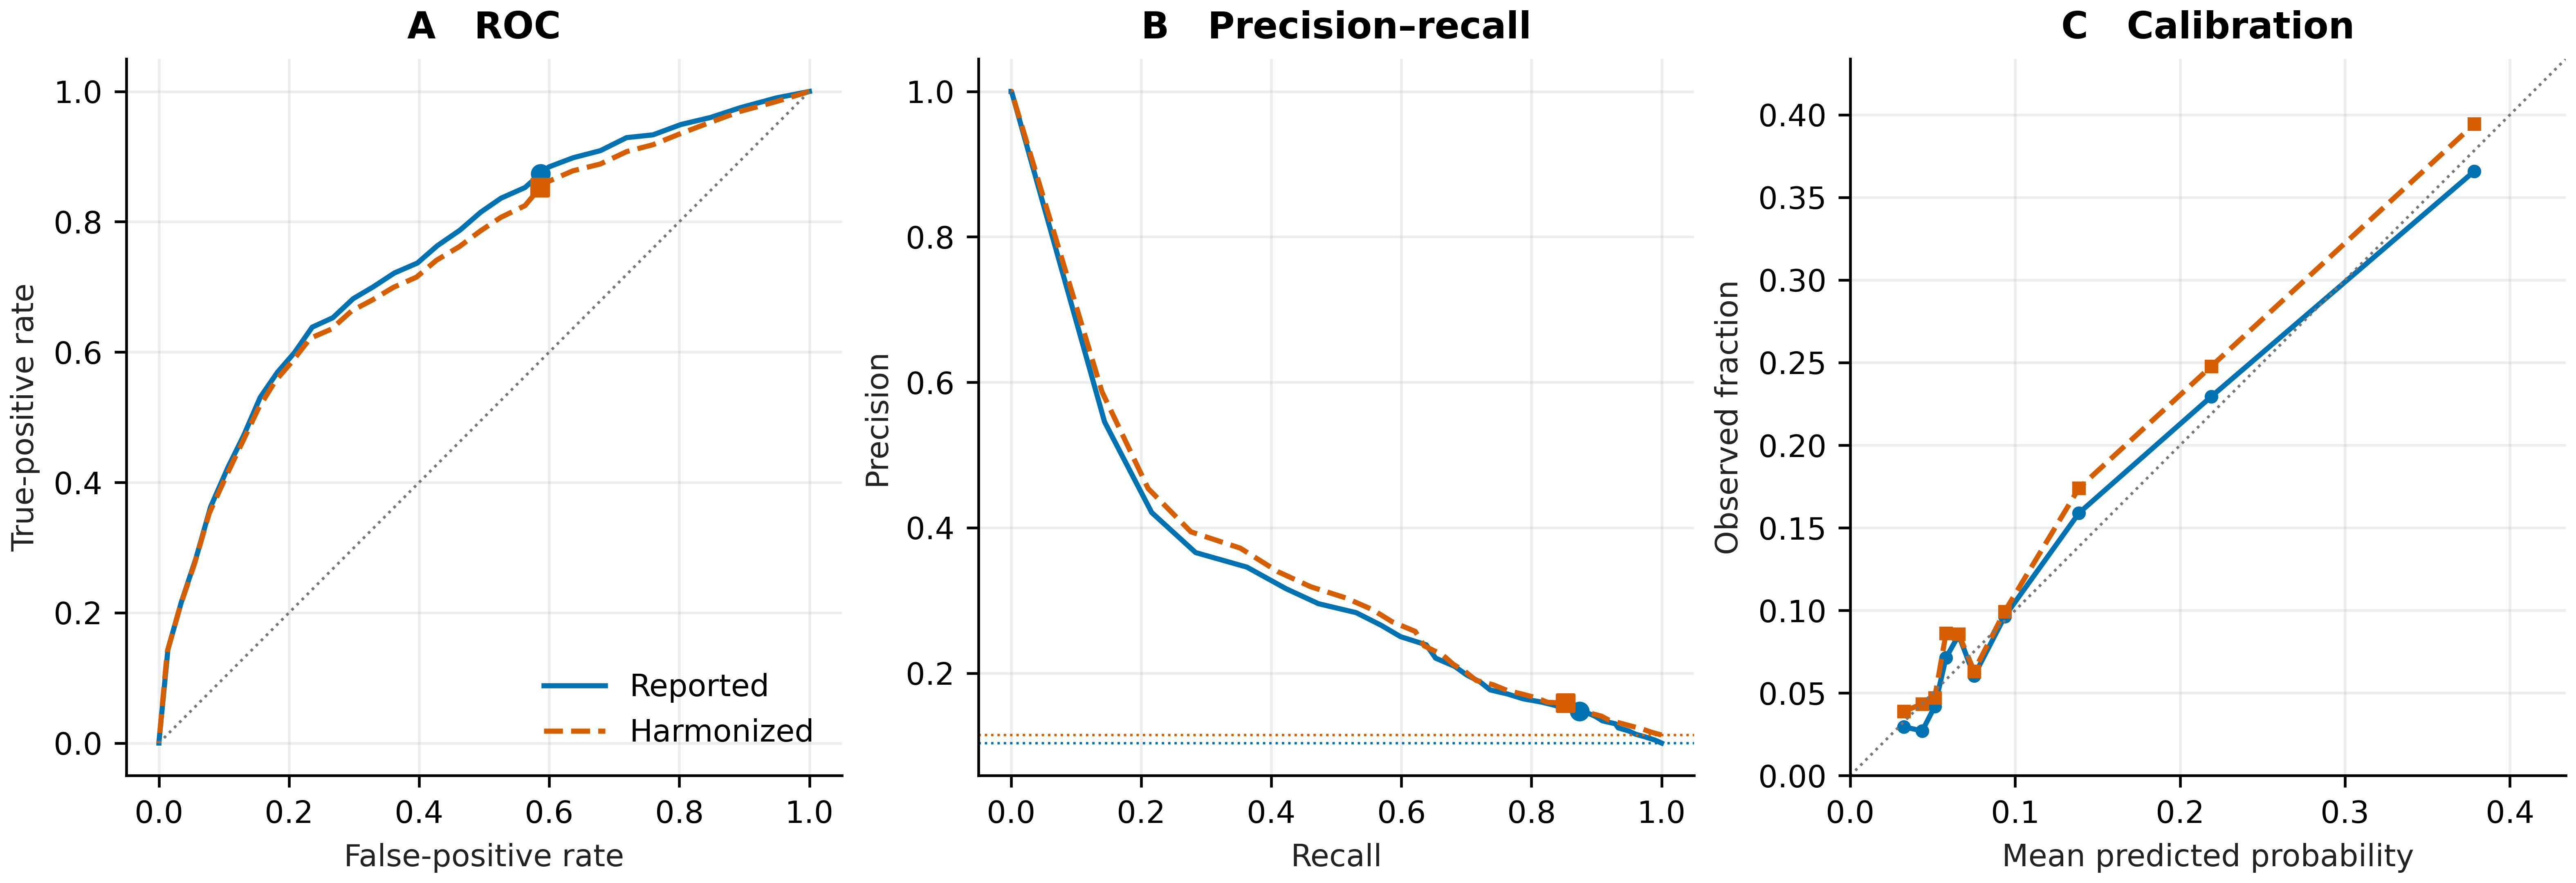


Figure 3A–B values. Displayed thresholds; metrics above use all scores

Definition	Threshold	Recall or TPR	FPR	Precision	Frozen operating point
Reported	0	1	1	0.103931	False
Reported	0.0172456	1	1	0.103931	False
Reported	0.0306809	0.990025	0.94894	0.107945	False
Reported	0.03531	0.975092	0.89389	0.112312	False
Reported	0.0389003	0.960087	0.848097	0.116062	False
Reported	0.0424	0.94935	0.802779	0.120618	False
Reported	0.0453881	0.933405	0.759514	0.124757	False
Reported	0.0477549	0.929151	0.718964	0.130354	False
Reported	0.0502559	0.90914	0.678688	0.134476	False
Reported	0.0525607	0.898311	0.636904	0.140591	False
Reported	0.0547239	0.884166	0.599516	0.146069	False
Reported	0.0555973	0.873656	0.58662	0.147294	True
Reported	0.0568628	0.852585	0.562906	0.149424	False
Reported	0.0593742	0.836186	0.525924	0.155697	False
Reported	0.0620209	0.814792	0.494831	0.160357	False
Reported	0.0644862	0.787149	0.462824	0.164761	False
Reported	0.0671366	0.763142	0.42786	0.171414	False
Reported	0.0697372	

In [11]:
labels = {"Reported": new.y_reported.to_numpy(), "Harmonized": new.y_harmonized.to_numpy()}
p = p_new["XGBoost"]
cutoff = thresholds["XGBoost"]
plot_cutoffs = np.unique(np.r_[0, np.quantile(p, np.linspace(0, 1, 31)), cutoff, np.nextafter(p.max(), np.inf)])
roc_rows, cal_rows = [], []
prob_bins = pd.qcut(p, q=10, labels=False, duplicates="drop")
for label, y in labels.items():
    for threshold in plot_cutoffs:
        yes = p >= threshold
        tp = w_new[(y == 1) & yes].sum()
        fp = w_new[(y == 0) & yes].sum()
        roc_rows.append((label, threshold, ratio(tp, w_new[y == 1].sum()), ratio(fp, w_new[y == 0].sum()),
                         ratio(tp, tp + fp) if yes.any() else 1.0, threshold == cutoff))
    for b in np.unique(prob_bins):
        keep = prob_bins == b
        cal_rows.append((label, int(b) + 1, keep.sum(), p[keep].min(), p[keep].max(),
                         wmean(p[keep], w_new[keep]), wmean(y[keep], w_new[keep])))
curves = pd.DataFrame(roc_rows, columns=["Definition", "Threshold", "Recall or TPR", "FPR", "Precision", "Frozen operating point"])
cal_points = pd.DataFrame(cal_rows, columns=["Definition", "Score bin", "Sample n", "Minimum score", "Maximum score", "Mean predicted probability", "Weighted observed fraction"])
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.6))
for label, color, style, marker in [("Reported", COLORS["earlier"], "-", "o"), ("Harmonized", COLORS["later"], "--", "s")]:
    r = curves[curves.Definition.eq(label)]
    c = cal_points[cal_points.Definition.eq(label)]
    ax[0].plot(r.FPR, r["Recall or TPR"], color=color, linestyle=style, label=label)
    ax[1].plot(r["Recall or TPR"], r.Precision, color=color, linestyle=style)
    ax[1].axhline(wmean(labels[label], w_new), color=color, linewidth=0.7, linestyle=":")
    ax[2].plot(c["Mean predicted probability"], c["Weighted observed fraction"], color=color, linestyle=style, marker=marker, markersize=3)
    op = r.loc[r["Frozen operating point"]].iloc[0]
    ax[0].scatter(op.FPR, op["Recall or TPR"], marker=marker, color=color, s=23, zorder=4)
    ax[1].scatter(op["Recall or TPR"], op.Precision, marker=marker, color=color, s=23, zorder=4)
ax[0].plot([0, 1], [0, 1], ":", color=COLORS["muted"], linewidth=0.8)
limit = max(0.22, cal_points[["Mean predicted probability", "Weighted observed fraction"]].to_numpy().max() * 1.10)
ax[2].plot([0, limit], [0, limit], ":", color=COLORS["muted"], linewidth=0.8)
ax[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="A   ROC")
ax[1].set(xlabel="Recall", ylabel="Precision", title="B   Precision–recall")
ax[2].set(xlim=(0, limit), ylim=(0, limit), xlabel="Mean predicted probability", ylabel="Observed fraction", title="C   Calibration")
ax[0].legend(loc="lower right")
show_figure(fig, ("Figure 3A–B values. Displayed thresholds; metrics above use all scores", curves),
            ("Figure 3B precision references", pd.DataFrame([(k, wmean(y, w_new)) for k, y in labels.items()], columns=["Definition", "Weighted prevalence"])),
            ("Figure 3C values. Weighted equal-count score-bin summaries", cal_points))

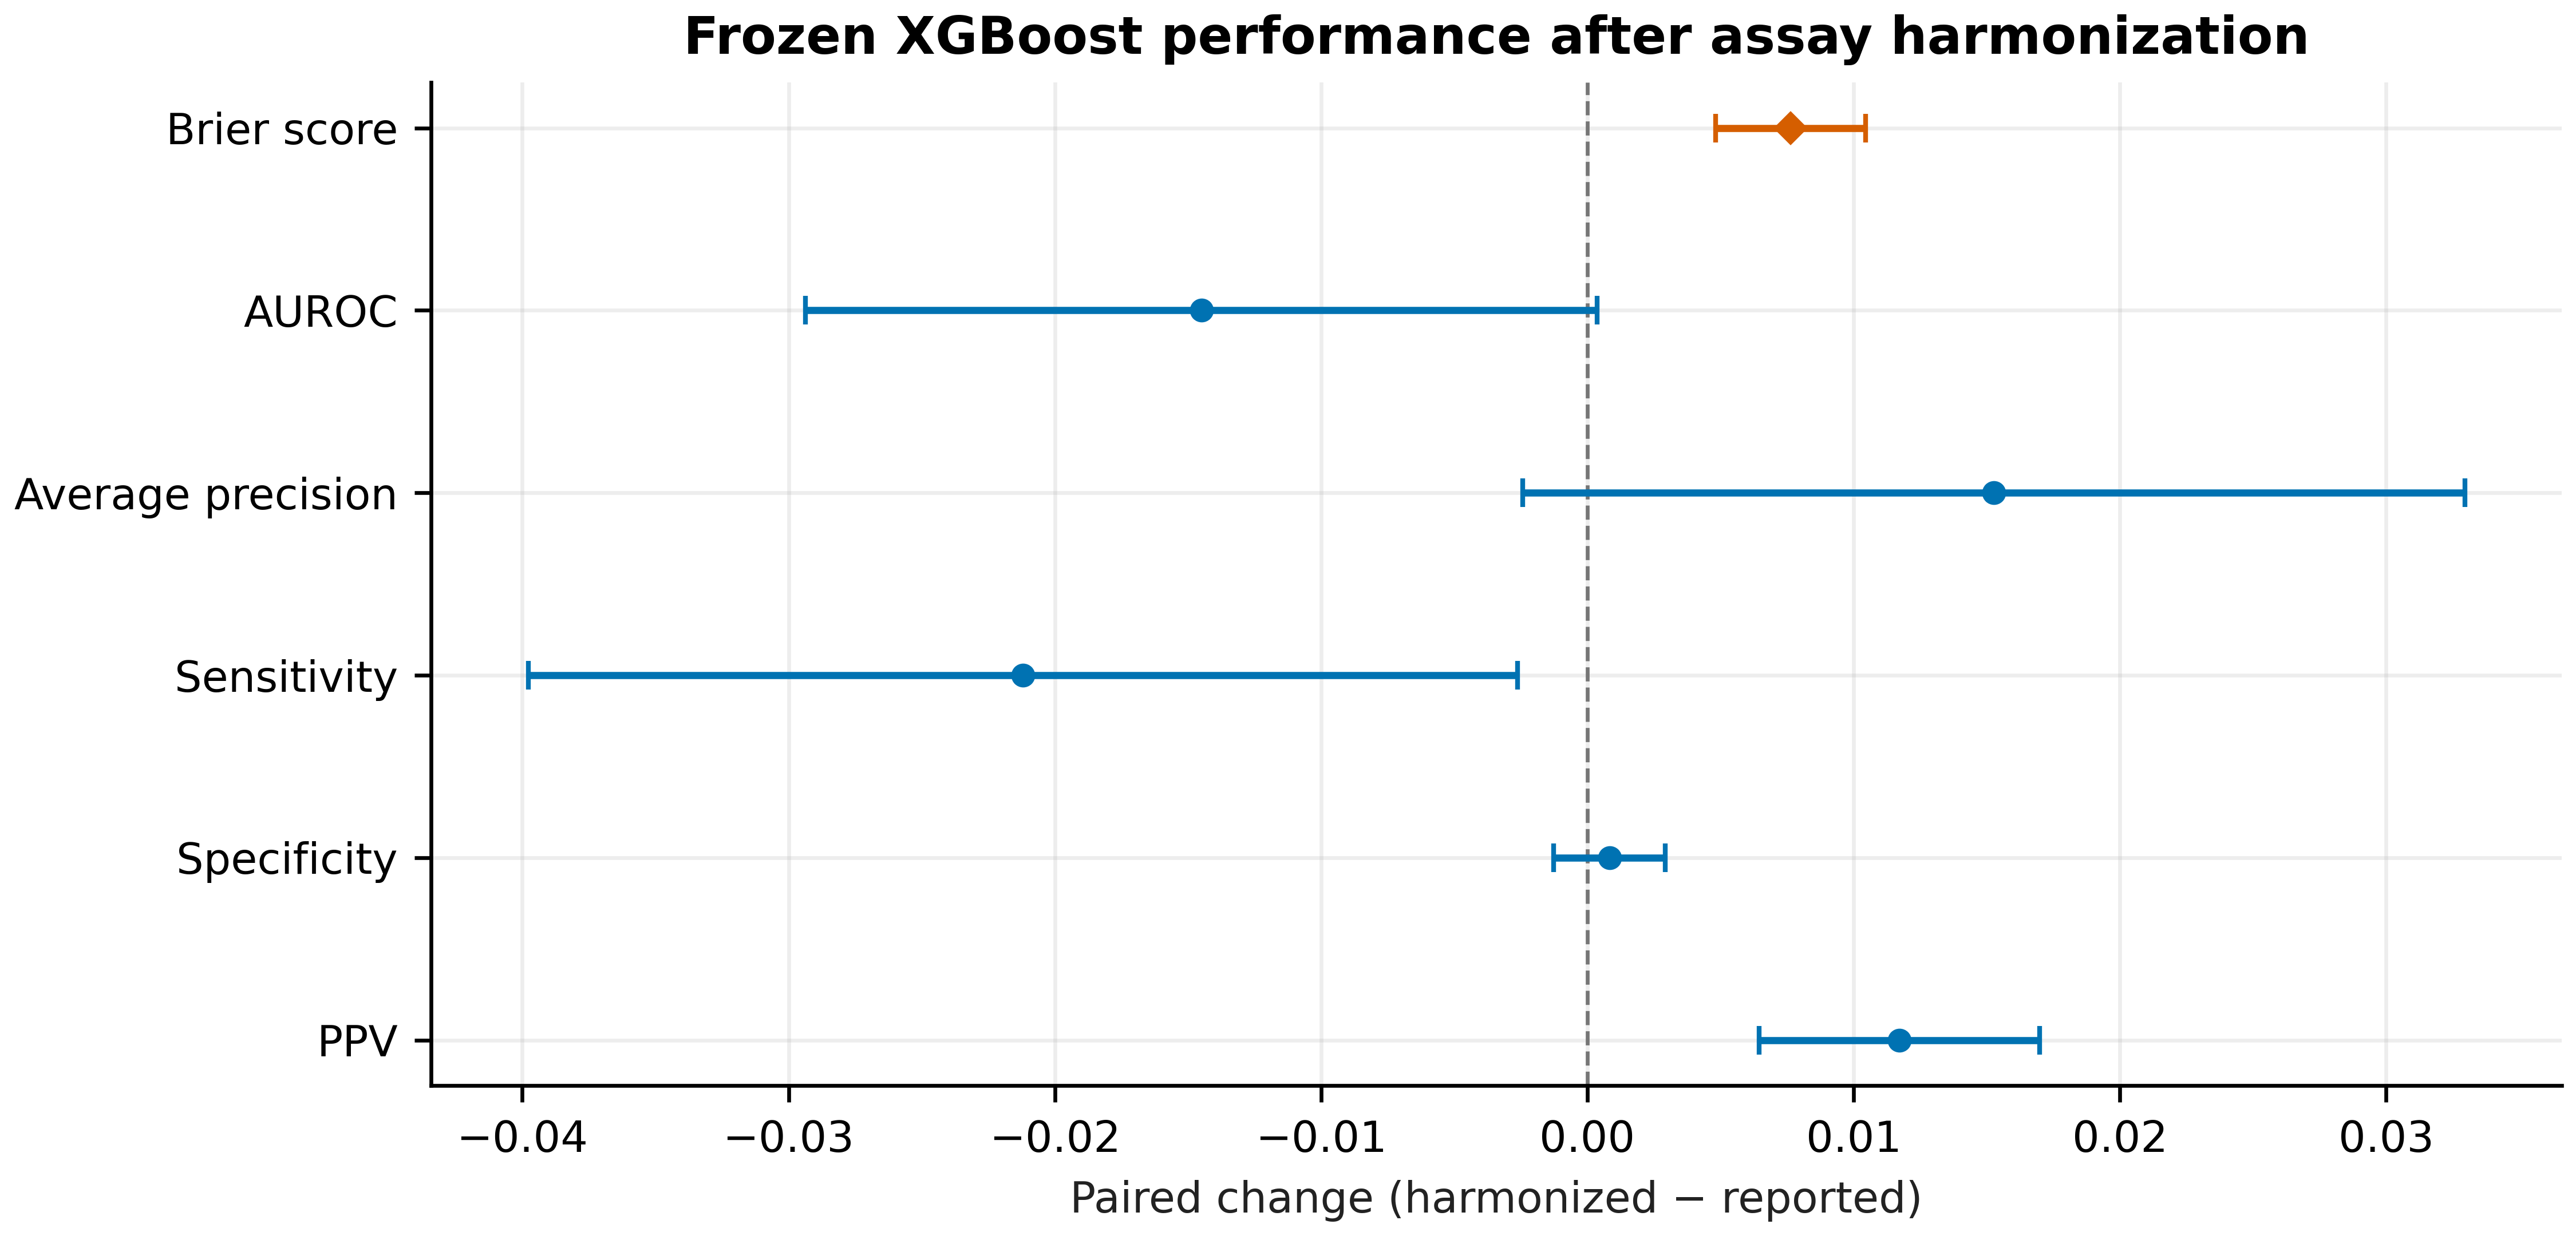


Figure 4 values. Point changes with 95% Fay BRR intervals

Model	Metric	Status	Estimate	SE	95% CI low	95% CI high	p
XGBoost	Brier score	Primary	0.00763413	0.00132409	0.00481191	0.0104564	3.72913e-05
XGBoost	AUROC	Secondary	-0.0145004	0.00697791	-0.0293734	0.000372702	NA
XGBoost	Average precision	Secondary	0.0152634	0.00830016	-0.00242793	0.0329548	NA
XGBoost	Sensitivity	Secondary	-0.0212057	0.00871591	-0.0397832	-0.00262816	NA
XGBoost	Specificity	Secondary	0.000831473	0.000985749	-0.0012696	0.00293255	NA
XGBoost	PPV	Secondary	0.0117174	0.00247327	0.00644579	0.0169891	NA


In [12]:
key_metrics = ["Brier score", "AUROC", "Average precision", "Sensitivity", "Specificity", "PPV"]
sort_by = {m: i for i, m in enumerate(key_metrics)}
forest = paired.loc[paired.Model.eq("XGBoost") & paired.Metric.isin(key_metrics)].copy()
forest["Order"] = forest.Metric.map(sort_by)
forest = forest.sort_values("Order").drop(columns="Order")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axvline(0, color=COLORS["muted"], linestyle="--", linewidth=0.8)
for k, (_, r) in enumerate(forest.iterrows()):
    color = COLORS["later"] if r.Status == "Primary" else COLORS["earlier"]
    ax.errorbar(r.Estimate, k, xerr=[[r.Estimate - r["95% CI low"]], [r["95% CI high"] - r.Estimate]],
                fmt="D" if r.Status == "Primary" else "o", color=color, markersize=4, capsize=3)
ax.set(yticks=range(len(forest)), yticklabels=forest.Metric, xlabel="Paired change (harmonized − reported)",
       title="Frozen XGBoost performance after assay harmonization")
ax.invert_yaxis()
show_figure(fig, ("Figure 4 values. Point changes with 95% Fay BRR intervals", forest))

## 6. Identify what drives the change and test robustness

Under a fixed probability \(p_i\), the individual Brier loss difference is \((y_{i,H}-y_{i,R})(1-2p_i)\). Only reclassified outcomes contribute. The first sensitivity analysis removes observations close to 30 mg/g under either outcome definition. The second restricts to complete predictors. These are outcome- or availability-defined descriptive subsets of the same later cycle. Their estimates describe the retained sample. No cutoffs or models are tuned within these subsets.


Primary variance cross-check using the paired loss and Taylor linearization

Paired Brier estimate	Fay BRR SE	Taylor linearization SE	Fay design df
0.00763413	0.00132409	0.00132744	15


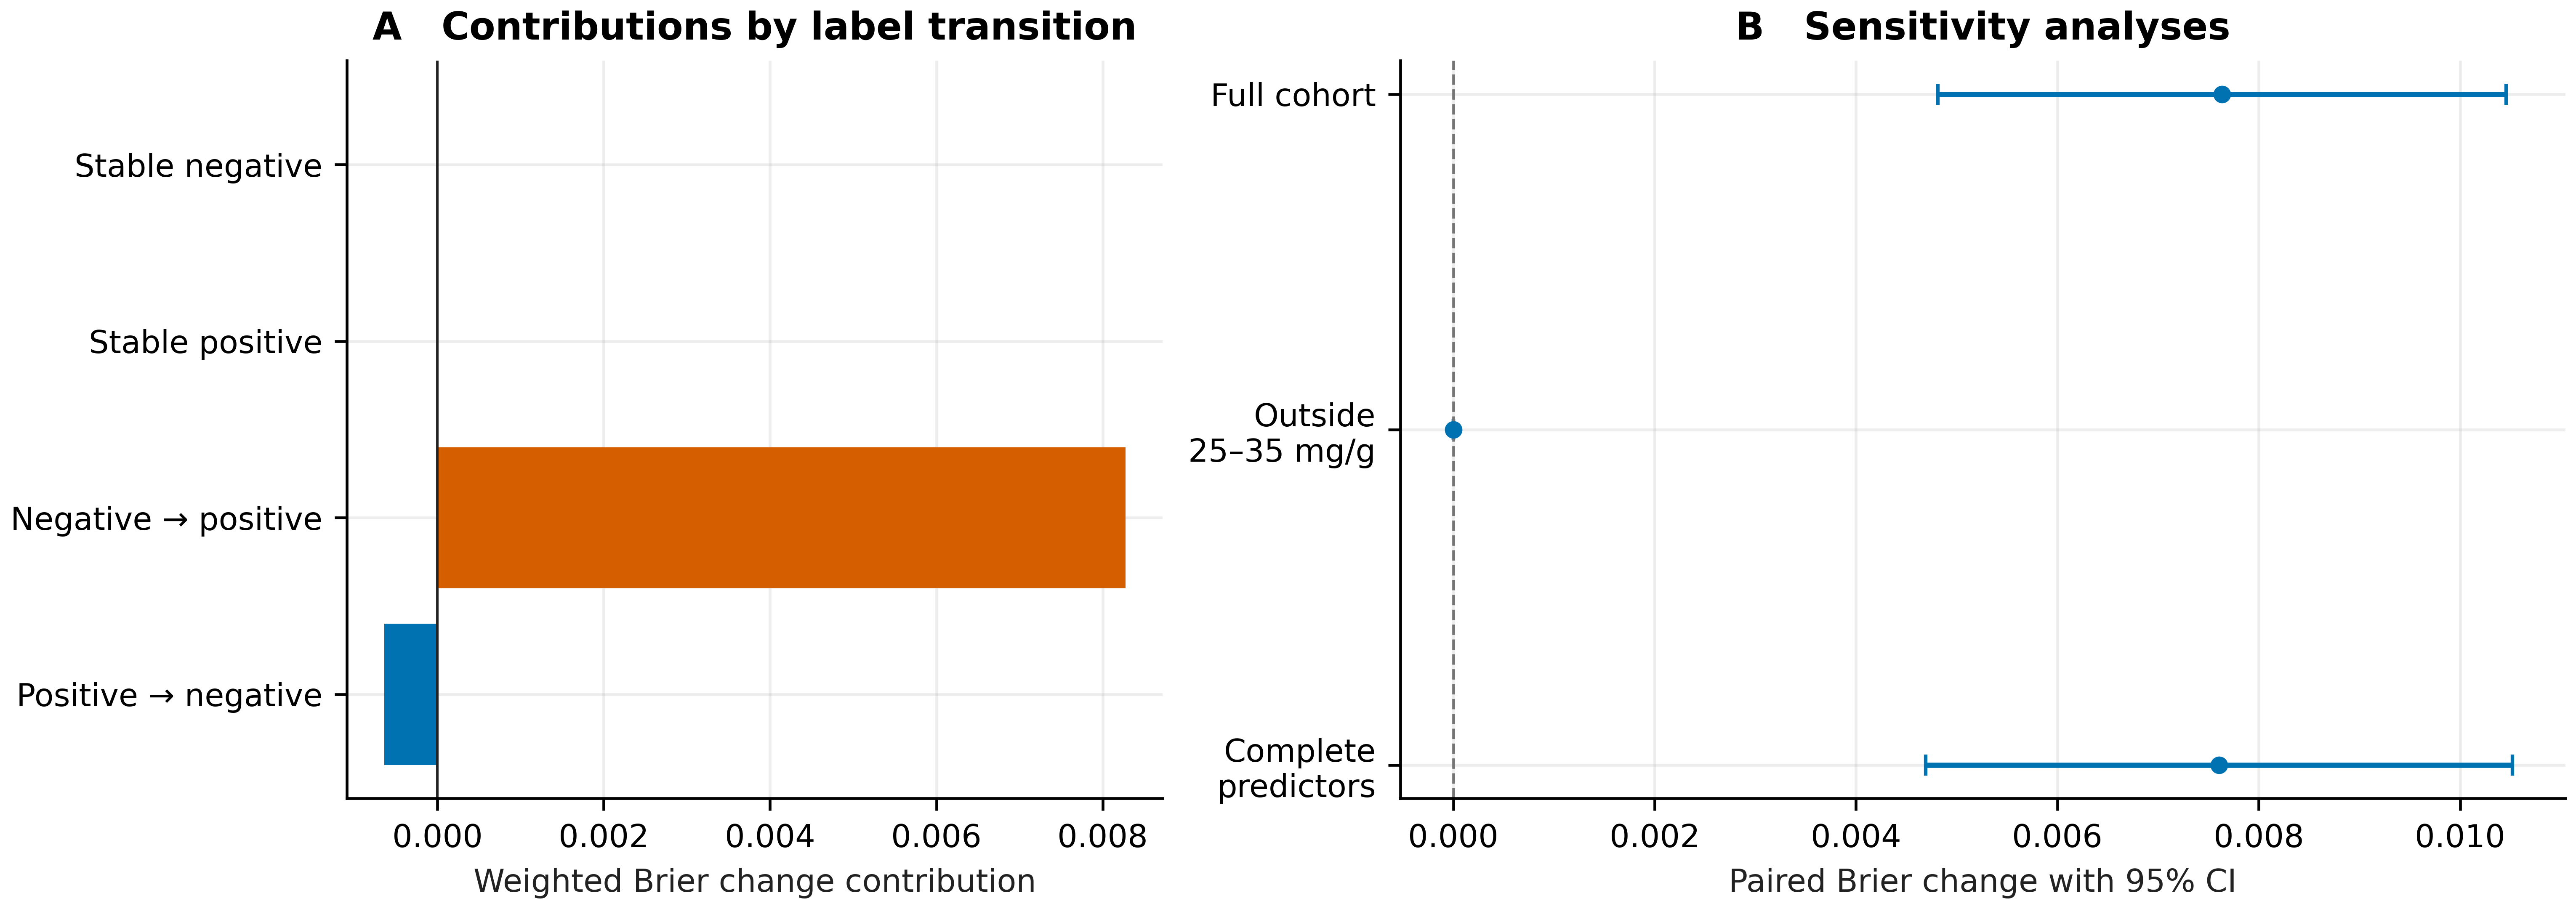


Figure 5A values. Brier loss decomposition

Transition	Sample n	Weighted fraction	Weighted median score	Contribution to Brier change
Stable negative	5079	0.884162	0.0617881	0
Stable positive	713	0.103083	0.168269	0
Negative → positive	72	0.011907	0.0703662	0.0082753
Positive → negative	6	0.000848116	0.0659993	-0.000641169

Figure 5B values. Robustness of the paired effect

Analysis population	Sample n	Changed labels	Estimate	SE	95% CI low	95% CI high
Full later cohort	5870	78	0.00763413	0.00132409	0.00481191	0.0104564
Outside 25–35 mg/g under both definitions	5560	0	0	0	0	0
All predictors observed	5528	72	0.00760755	0.00136687	0.00469412	0.010521


In [13]:
p = p_new["XGBoost"]
y_r, y_h = new.y_reported.to_numpy(), new.y_harmonized.to_numpy()
loss_delta = (p - y_h) ** 2 - (p - y_r) ** 2
identity = (y_h - y_r) * (1 - 2 * p)
assert np.allclose(loss_delta, identity)
primary_row = paired.loc[paired.Status.eq("Primary")].iloc[0]
assert np.isclose(wmean(identity, w_new), primary_row.Estimate)
linearized = w_new * (identity - primary_row.Estimate) / w_new.sum()
psu_totals = new.assign(influence=linearized).groupby(["SDMVSTRA", "SDMVPSU"]).influence.sum().unstack()
assert psu_totals.shape[1] == 2 and psu_totals.notna().all().all()
taylor_se = float(np.linalg.norm(psu_totals.iloc[:, 0] - psu_totals.iloc[:, 1]))
audit = pd.DataFrame([{"Paired Brier estimate": primary_row.Estimate, "Fay BRR SE": primary_row.SE,
                       "Taylor linearization SE": taylor_se, "Fay design df": df_new}])
table("Primary variance cross-check using the paired loss and Taylor linearization", audit)

components = []
for name, mask in [("Stable negative", (y_r == 0) & (y_h == 0)), ("Stable positive", (y_r == 1) & (y_h == 1)),
                   ("Negative → positive", y_h > y_r), ("Positive → negative", y_h < y_r)]:
    _, med, _ = wquantile(p[mask], [0.25, 0.50, 0.75], w_new[mask])
    components.append((name, mask.sum(), wmean(mask, w_new), med, float(np.dot(w_new[mask], identity[mask]) / w_new.sum())))
loss_parts = pd.DataFrame(components, columns=["Transition", "Sample n", "Weighted fraction", "Weighted median score", "Contribution to Brier change"])
assert np.isclose(loss_parts["Contribution to Brier change"].sum(), primary_row.Estimate)

away = ~(new.uacr_reported.between(25, 35) | new.uacr_harmonized.between(25, 35))
complete = new[FEATURES].notna().all(axis=1)
sensitivity_rows = []
for name, selector in [("Full later cohort", np.ones(len(new), dtype=bool)), ("Outside 25–35 mg/g under both definitions", away.to_numpy()),
                       ("All predictors observed", complete.to_numpy())]:
    result = brr_summary(wmean(identity[selector], w_new[selector]),
                         [wmean(identity[selector], w[selector]) for w in rep_new], df_new)
    result.pop("p")
    sensitivity_rows.append({"Analysis population": name, "Sample n": selector.sum(), "Changed labels": (y_r[selector] != y_h[selector]).sum(), **result})
sensitivity = pd.DataFrame(sensitivity_rows)
fig, ax = plt.subplots(1, 2, figsize=(10.2, 3.6), gridspec_kw={"width_ratios": [1.05, 1.5]})
ax[0].barh(loss_parts.Transition, loss_parts["Contribution to Brier change"], color=[COLORS["muted"], COLORS["muted"], COLORS["later"], COLORS["earlier"]])
ax[0].axvline(0, color=COLORS["ink"], linewidth=0.7)
ax[0].set(xlabel="Weighted Brier change contribution", title="A   Contributions by label transition")
ax[0].invert_yaxis()
for i, row in sensitivity.iterrows():
    ax[1].errorbar(row.Estimate, i, xerr=[[row.Estimate - row["95% CI low"]], [row["95% CI high"] - row.Estimate]],
                   color=COLORS["earlier"], fmt="o", markersize=4, capsize=3)
ax[1].axvline(0, color=COLORS["muted"], linestyle="--", linewidth=0.8)
ax[1].set(yticks=list(range(len(sensitivity))), yticklabels=["Full cohort", "Outside\n25–35 mg/g", "Complete\npredictors"],
          xlabel="Paired Brier change with 95% CI", title="B   Sensitivity analyses")
ax[1].invert_yaxis()
show_figure(fig, ("Figure 5A values. Brier loss decomposition", loss_parts), ("Figure 5B values. Robustness of the paired effect", sensitivity))

## 7. Check explanation transport and isolate the effect of label harmonization on learning

All explanations use interventional TreeSHAP on XGBoost raw log-odds. Each comparison uses one fixed reference distribution drawn from the relevant training set only. For the frozen model, a difference across cohorts reflects a change in the data presented to the model, which can include shifts in the feature distribution and missingness. Relabelling the unseen evaluation data leaves these predictions and attributions identical. For paired refits, the comparison changes only the training label definition and evaluates both fitted models on the same feature rows with the same preprocessing and SHAP settings.

Mean absolute SHAP measures how much a model relies on a feature in the evaluation cohort. Correlated measurements such as BMI and waist circumference can share or exchange importance. Compare individual features alongside grouped anthropometry, blood pressure, and diabetes attributions. The group importance is the weighted mean of the absolute sum of its signed member attributions per participant. Grouped importance is therefore distinct from the sum of individual importances. See [TreeExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

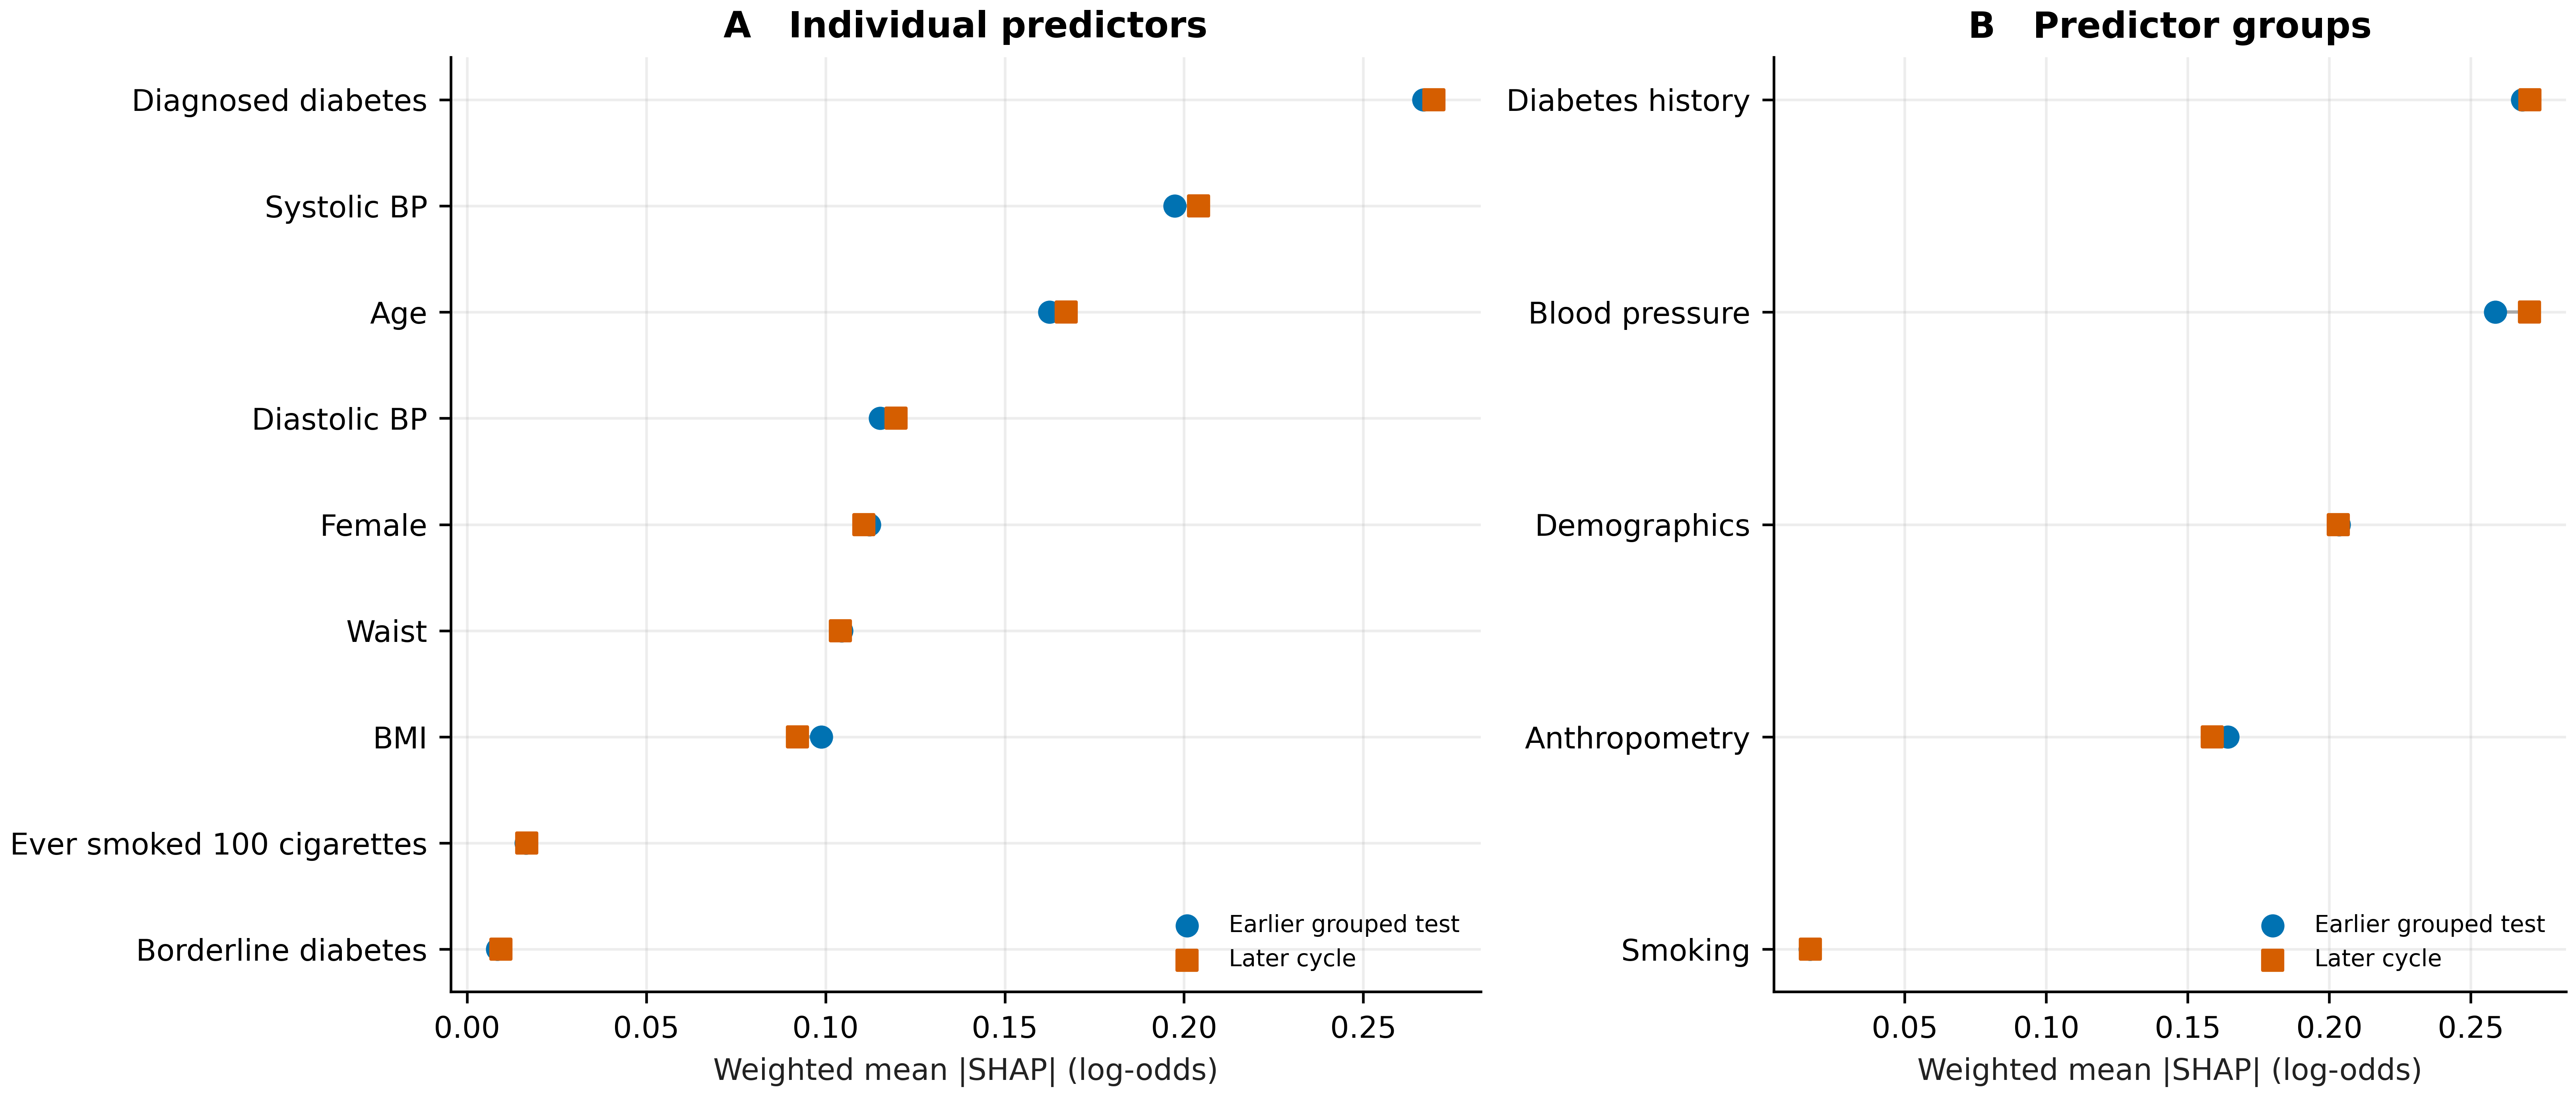


Figure 6A values. Frozen-model SHAP by cohort

Predictor	Earlier grouped test	Later cycle	Earlier grouped test rank	Later cycle rank	Change
Diagnosed diabetes	0.266849	0.269662	1	1	0.00281272
Systolic BP	0.197377	0.20407	2	2	0.00669339
Age	0.162446	0.16709	3	3	0.00464427
Diastolic BP	0.11521	0.119707	4	4	0.00449696
Female	0.112237	0.110724	5	5	-0.00151215
Waist	0.104462	0.104182	6	6	-0.000280614
BMI	0.0988676	0.0921757	7	7	-0.00669186
Ever smoked 100 cigarettes	0.0164944	0.0166787	8	8	0.000184323
Borderline diabetes	0.0085135	0.00951095	9	9	0.000997452

Figure 6B values. Grouped SHAP by cohort

Predictor	Earlier grouped test	Later cycle	Earlier grouped test rank	Later cycle rank	Change
Diabetes history	0.268187	0.270941	1	1	0.00275386
Blood pressure	0.258629	0.270674	2	2	0.0120459
Demographics	0.203426	0.20323	3	3	-0.000196154
Anthropometry	0.164187	0.158686	4	4	-0.00550113
Smoking	0.0164944	0.0166787	5	5	0.000184323

Frozen-model explanation checks

Spearman rank correlation	Backgrou

In [14]:
def fixed_background(x, seed):
    return x.sample(n=min(BACKGROUND_SIZE, len(x)), random_state=seed)

def tree_shap(model, x, background):
    explainer = shap.TreeExplainer(model, data=background, feature_perturbation="interventional", model_output="raw")
    values = np.asarray(explainer.shap_values(x, check_additivity=False))
    baseline = float(np.asarray(explainer.expected_value).item())
    margins = model.predict(x, output_margin=True)
    max_error = float(np.max(np.abs(values.sum(axis=1) + baseline - margins)))
    assert values.shape == x.shape
    assert np.isfinite(values).all() and max_error < 1e-4, f"SHAP additivity check: {max_error}"
    return pd.DataFrame(values, columns=x.columns), baseline, max_error

def importance(shap_frame, weights):
    return pd.Series(np.average(np.abs(shap_frame), axis=0, weights=weights), index=shap_frame.columns)

def ranked(values):
    return values.rank(method="average", ascending=False)

def importance_compare(a, b, wa, wb, a_label, b_label):
    importance_a, importance_b = importance(a, wa), importance(b, wb)
    return pd.DataFrame({"Predictor": importance_a.index, a_label: importance_a.values, b_label: importance_b.values,
                         a_label + " rank": ranked(importance_a).values, b_label + " rank": ranked(importance_b).values,
                         "Change": (importance_b - importance_a).values}).sort_values(a_label, ascending=False).reset_index(drop=True)

def cluster_attributions(frame):
    return pd.DataFrame({"Demographics": frame[["Age", "Female"]].sum(axis=1),
                         "Anthropometry": frame[["BMI", "Waist"]].sum(axis=1),
                         "Blood pressure": frame[["Systolic BP", "Diastolic BP"]].sum(axis=1),
                         "Smoking": frame["Ever smoked 100 cigarettes"],
                         "Diabetes history": frame[["Diagnosed diabetes", "Borderline diabetes"]].sum(axis=1)})

def importance_panel(ax, values, a_label, b_label, title):
    ys = np.arange(len(values))
    for k, (_, row) in enumerate(values.iterrows()):
        ax.plot([row[a_label], row[b_label]], [k, k], color="#A9A9A9", linewidth=1.0, zorder=1)
    ax.scatter(values[a_label], ys, color=COLORS["earlier"], marker="o", label=a_label, zorder=3)
    ax.scatter(values[b_label], ys, color=COLORS["later"], marker="s", label=b_label, zorder=3)
    ax.set(yticks=ys, yticklabels=values.Predictor, xlabel="Weighted mean |SHAP| (log-odds)", title=title)
    ax.invert_yaxis()
    ax.legend(loc="lower right", fontsize=7)

old_prep, old_xgb, old_cols = frozen["XGBoost"]
background = fixed_background(old_prep.transform(old_train[old_cols]), SEED + 3)
phi_old, old_base, old_err = tree_shap(old_xgb, old_prep.transform(old_test[old_cols]), background)
phi_new, new_base, new_err = tree_shap(old_xgb, old_prep.transform(new[old_cols]), background)
assert np.isclose(old_base, new_base)
frozen_importance = importance_compare(phi_old, phi_new, old_test.w, new.w, "Earlier grouped test", "Later cycle")
frozen_groups = importance_compare(cluster_attributions(phi_old), cluster_attributions(phi_new), old_test.w, new.w, "Earlier grouped test", "Later cycle")
frozen_rho = spearmanr(frozen_importance["Earlier grouped test"], frozen_importance["Later cycle"]).statistic
fig, ax = plt.subplots(1, 2, figsize=(10.8, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
importance_panel(ax[0], frozen_importance, "Earlier grouped test", "Later cycle", "A   Individual predictors")
importance_panel(ax[1], frozen_groups, "Earlier grouped test", "Later cycle", "B   Predictor groups")
show_figure(fig, ("Figure 6A values. Frozen-model SHAP by cohort", frozen_importance),
            ("Figure 6B values. Grouped SHAP by cohort", frozen_groups),
            ("Frozen-model explanation checks", pd.DataFrame([{"Spearman rank correlation": frozen_rho, "Background n": len(background),
               "Baseline log-odds": old_base, "Earlier maximum additivity residual": old_err, "Later maximum additivity residual": new_err}])))


Table 8. Paired-refit prediction metrics on the identical later holdout

Model	Evaluation definition	AUROC	Average precision	Brier score	Log loss	Calibration intercept	Calibration slope
Reported refit	Reported	0.72494	0.297363	0.0879504	0.309805	0.163581	0.798497
Reported refit	Harmonized	0.717515	0.319921	0.0957826	0.335119	0.298698	0.785784
Harmonized refit	Reported	0.728953	0.291434	0.0884847	0.308597	0.0224577	0.831633
Harmonized refit	Harmonized	0.719601	0.31918	0.0957704	0.331753	0.155578	0.822581


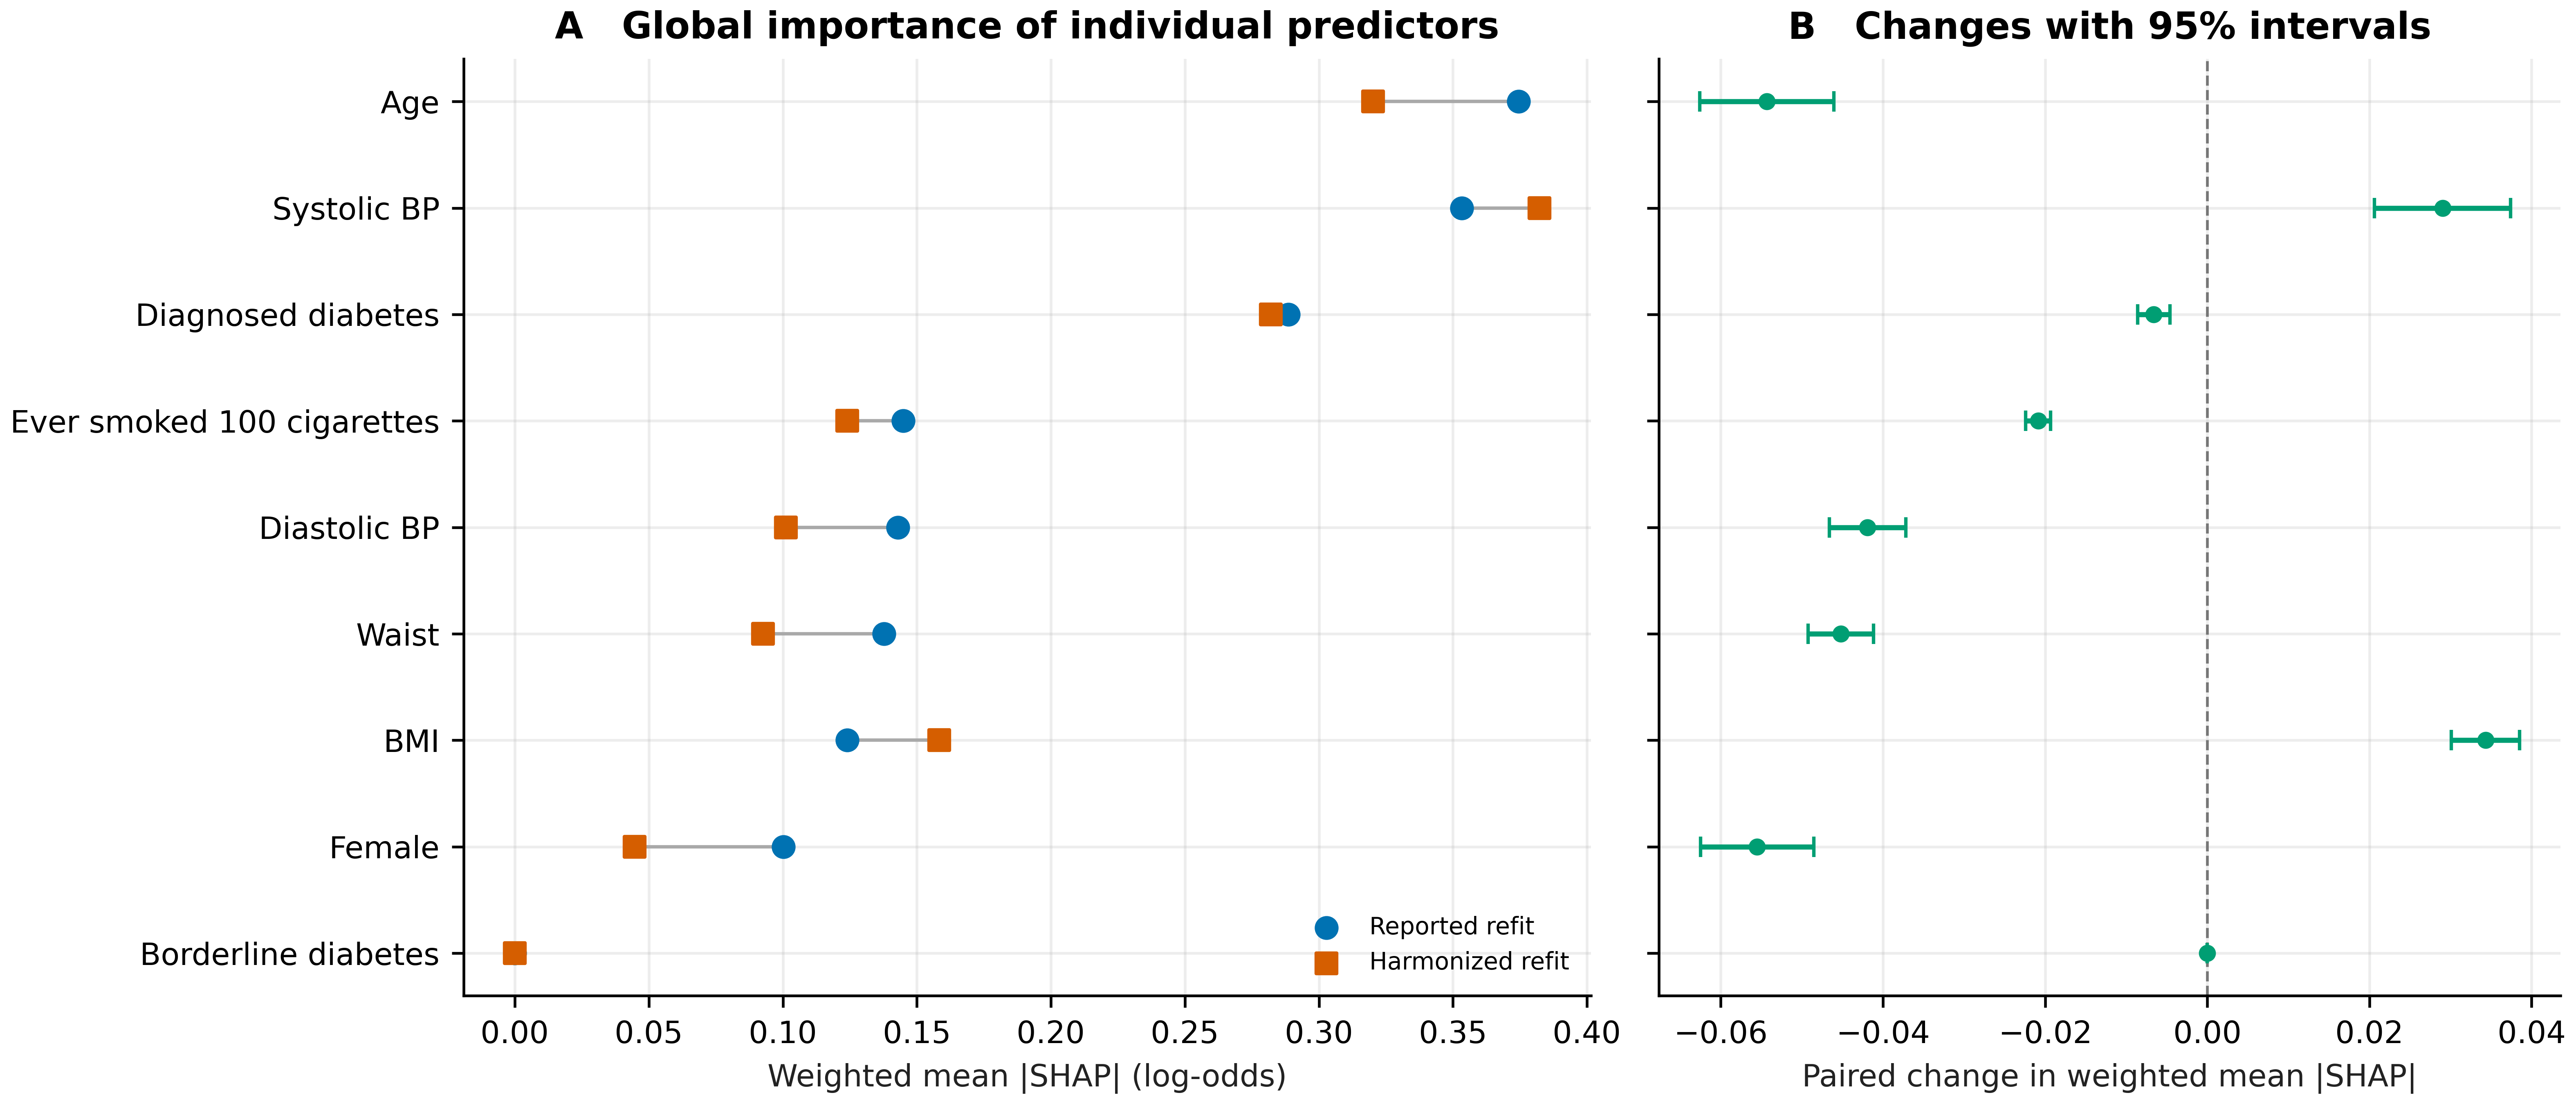


Figure 7A–B values. Shared holdout paired SHAP comparison

Predictor	Reported refit	Harmonized refit	Reported refit rank	Harmonized refit rank	Change	95% CI low	95% CI high
Age	0.374569	0.320247	1	2	-0.0543219	-0.0625936	-0.0460501
Systolic BP	0.35332	0.38236	2	1	0.0290396	0.0206421	0.0374371
Diagnosed diabetes	0.288605	0.282009	3	3	-0.0065968	-0.00857824	-0.00461535
Ever smoked 100 cigarettes	0.144938	0.12408	4	5	-0.0208581	-0.0224029	-0.0193134
Diastolic BP	0.142967	0.101067	5	6	-0.0419004	-0.0465998	-0.0372011
Waist	0.137718	0.092521	6	7	-0.0451966	-0.0492504	-0.0411427
BMI	0.124039	0.158362	7	4	0.0343223	0.030117	0.0385276
Female	0.100275	0.0447522	8	8	-0.0555228	-0.0625061	-0.0485396
Borderline diabetes	0	0	9	9	0	0	0

Grouped explanation sensitivity on the same holdout

Predictor	Reported refit	Harmonized refit	Reported refit rank	Harmonized refit rank	Change	95% CI low	95% CI high
Demographics	0.395403	0.32425	1	2	-0.0711534	-0.0849536	-0.0573532
Blood pressure	0.384358	0.411837

In [15]:
shared_prep = make_preprocessor(FEATURES)
x_refit_train = shared_prep.fit_transform(refit_train[FEATURES])
x_refit_test = shared_prep.transform(refit_test[FEATURES])
shared_background = fixed_background(x_refit_train, SEED + 4)
paired_models = {
    label: fit_estimator("XGBoost", x_refit_train, refit_train[column], refit_train.w)
    for label, column in [("Reported refit", "y_reported"), ("Harmonized refit", "y_harmonized")]
}
refit_shap = {key: tree_shap(model, x_refit_test, shared_background) for key, model in paired_models.items()}
refit_scores = {key: mdl.predict_proba(x_refit_test)[:, 1] for key, mdl in paired_models.items()}
a_name, b_name = paired_models.keys()
phi_a, base_a, residual_a = refit_shap[a_name]
phi_b, base_b, residual_b = refit_shap[b_name]
refit_importance = importance_compare(phi_a, phi_b, w_refit, w_refit, a_name, b_name)
refit_groups = importance_compare(cluster_attributions(phi_a), cluster_attributions(phi_b), w_refit, w_refit, a_name, b_name)
for importance_table, shap_a, shap_b in [(refit_importance, phi_a, phi_b),
                                         (refit_groups, cluster_attributions(phi_a), cluster_attributions(phi_b))]:
    diffs = np.abs(shap_b) - np.abs(shap_a)
    for col in ["95% CI low", "95% CI high"]:
        importance_table[col] = np.nan
    for i, row in importance_table.iterrows():
        delta = diffs[row.Predictor].to_numpy()
        stats = brr_summary(row.Change, (rep_refit @ delta) / rep_refit.sum(axis=1), df_refit)
        importance_table.loc[i, ["95% CI low", "95% CI high"]] = [stats["95% CI low"], stats["95% CI high"]]

# Models are evaluated against each label definition on their common untouched holdout.
refit_evaluation = []
for name, preds in refit_scores.items():
    for label, y in [("Reported", refit_test.y_reported), ("Harmonized", refit_test.y_harmonized)]:
        vals = metric_set(y, preds, w_refit, thresholds["XGBoost"])
        keep = ["AUROC", "Average precision", "Brier score", "Log loss", "Calibration intercept", "Calibration slope"]
        refit_evaluation.append({"Model": name, "Evaluation definition": label, **{metric: vals[metric] for metric in keep}})
table("Table 8. Paired-refit prediction metrics on the identical later holdout", pd.DataFrame(refit_evaluation))

abs_a, abs_b = np.abs(phi_a.to_numpy()), np.abs(phi_b.to_numpy())
order_a = np.argsort(-abs_a, axis=1, kind="stable")
order_b = np.argsort(-abs_b, axis=1, kind="stable")
top_agreement = order_a[:, 0] == order_b[:, 0]
jaccard_top3 = np.array([len(set(a[:3]) & set(b[:3])) / len(set(a[:3]) | set(b[:3])) for a, b in zip(order_a, order_b)])
delta_scores = refit_scores[b_name] - refit_scores[a_name]
local_quantities = {
    "Top-ranked absolute attribution agrees (proportion)": top_agreement,
    "Top-three absolute attribution Jaccard similarity": jaccard_top3,
    "Absolute probability change": np.abs(delta_scores),
    "Signed probability change": delta_scores,
}
local_rows = []
for name, values in local_quantities.items():
    stats = brr_summary(wmean(values, w_refit), (rep_refit @ values) / rep_refit.sum(axis=1), df_refit)
    stats.pop("p")
    local_rows.append({"Measure": name, **stats})
refit_rank_rho = spearmanr(refit_importance[a_name], refit_importance[b_name]).statistic
local_summary = pd.DataFrame(local_rows)

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.5), gridspec_kw={"width_ratios": [1.25, 1]})
importance_panel(ax[0], refit_importance, a_name, b_name, "A   Global importance of individual predictors")
ax[1].axvline(0, linestyle="--", color=COLORS["muted"], linewidth=0.8)
for j, row in refit_importance.iterrows():
    ax[1].errorbar(row.Change, j, xerr=[[row.Change - row["95% CI low"]], [row["95% CI high"] - row.Change]],
                   fmt="o", color=COLORS["accent"], markersize=4, capsize=3)
ax[1].set(yticks=range(len(refit_importance)), yticklabels=[], xlabel="Paired change in weighted mean |SHAP|", title="B   Changes with 95% intervals")
ax[1].invert_yaxis()
show_figure(fig, ("Figure 7A–B values. Shared holdout paired SHAP comparison", refit_importance),
            ("Grouped explanation sensitivity on the same holdout", refit_groups),
            ("Individual explanation and probability agreement", local_summary),
            ("Paired-refit explanation checks", pd.DataFrame([{"Spearman rank correlation": refit_rank_rho,
              "Background n": len(shared_background), "Reported baseline log-odds": base_a, "Harmonized baseline log-odds": base_b,
              "Reported maximum additivity residual": residual_a, "Harmonized maximum additivity residual": residual_b}])))

## 8. Results to report and limits of inference

The final summary prints the quantities that anchor the Results section. Report the primary effect size with its interval and the number of labels that changed. Present secondary estimates as exploratory with pointwise intervals. The precision–recall baseline changes when prevalence changes, so interpret average precision alongside each definition's prevalence. Separately report the direction and magnitude of changes in calibration and discrimination. Similar global feature rankings can coexist with different individual explanations.

**Limits.** The two periods differ in their sampling and data collection environments. The harmonization comparison holds the later participants fixed, whereas the earlier-versus-later transport comparison combines all changes across periods. Public survey weights account for the NHANES sampling design and its standard adjustments, with possible residual bias from outcome availability and predictor missingness. The complete-predictor sensitivity analysis describes a restricted subset. Known pregnancies are excluded and unreleased or indeterminate pregnancy status is retained. The CDC equation is a population-level bridge rather than a gold-standard paired remeasurement for each participant. The calculated intervals condition on fitted models and a single assay equation. Prospective clinical validation and single-patient diagnostic interpretation are separate questions.

In [16]:
r = paired.loc[paired.Status.eq("Primary")].iloc[0]
metrics_report = metrics_full.query("Model == 'XGBoost' and Evaluation == 'Later temporal test'").set_index("Definition")
summary = pd.DataFrame([
    ("Earlier development n", len(old_train)), ("Earlier grouped test n", len(old_test)),
    ("Later frozen evaluation n", len(new)), ("Later participants with changed labels", new.y_reported.ne(new.y_harmonized).sum()),
    ("Later weighted reported prevalence", metrics_report.at["Reported", "Prevalence"]),
    ("Later weighted harmonized prevalence", metrics_report.at["Harmonized", "Prevalence"]),
    ("Later reported AUROC", metrics_report.at["Reported", "AUROC"]),
    ("Later harmonized AUROC", metrics_report.at["Harmonized", "AUROC"]),
    ("Later reported Brier", metrics_report.at["Reported", "Brier score"]),
    ("Later harmonized Brier", metrics_report.at["Harmonized", "Brier score"]),
    ("Primary Brier contrast", r.Estimate), ("Primary 95% CI low", r["95% CI low"]),
    ("Primary 95% CI high", r["95% CI high"]), ("Primary two-sided p-value", r.p),
    ("Frozen explanation rank correlation across cycles", frozen_rho),
    ("Paired refit explanation rank correlation", refit_rank_rho),
    ("Paired refit local top-attribution agreement", wmean(top_agreement, w_refit)),
], columns=["Report item", "Value"])
table("Manuscript results summary", summary)


Manuscript results summary

Report item	Value
Earlier development n	6586
Earlier grouped test n	1648
Later frozen evaluation n	5870
Later participants with changed labels	78
Later weighted reported prevalence	0.103931
Later weighted harmonized prevalence	0.11499
Later reported AUROC	0.75337
Later harmonized AUROC	0.73887
Later reported Brier	0.0824155
Later harmonized Brier	0.0900496
Primary Brier contrast	0.00763413
Primary 95% CI low	0.00481191
Primary 95% CI high	0.0104564
Primary two-sided p-value	3.72913e-05
Frozen explanation rank correlation across cycles	1
Paired refit explanation rank correlation	0.883333
Paired refit local top-attribution agreement	0.756366
